# Unsupervised Learning: Trade & Ahead

## Problem Statement

### Context

The stock market has consistently proven to be a good place to invest in and save for the future. There are a lot of compelling reasons to invest in stocks. It can help in fighting inflation, create wealth, and also provides some tax benefits. Good steady returns on investments over a long period of time can also grow a lot more than seems possible. Also, thanks to the power of compound interest, the earlier one starts investing, the larger the corpus one can have for retirement. Overall, investing in stocks can help meet life's financial aspirations.

It is important to maintain a diversified portfolio when investing in stocks in order to maximise earnings under any market condition. Having a diversified portfolio tends to yield higher returns and face lower risk by tempering potential losses when the market is down. It is often easy to get lost in a sea of financial metrics to analyze while determining the worth of a stock, and doing the same for a multitude of stocks to identify the right picks for an individual can be a tedious task. By doing a cluster analysis, one can identify stocks that exhibit similar characteristics and ones which exhibit minimum correlation. This will help investors better analyze stocks across different market segments and help protect against risks that could make the portfolio vulnerable to losses.


### Objective

Trade&Ahead is a financial consultancy firm who provide their customers with personalized investment strategies. They have hired you as a Data Scientist and provided you with data comprising stock price and some financial indicators for a few companies listed under the New York Stock Exchange. They have assigned you the tasks of analyzing the data, grouping the stocks based on the attributes provided, and sharing insights about the characteristics of each group.

### Data Dictionary

- Ticker Symbol: An abbreviation used to uniquely identify publicly traded shares of a particular stock on a particular stock market
- Company: Name of the company
- GICS Sector: The specific economic sector assigned to a company by the Global Industry Classification Standard (GICS) that best defines its business operations
- GICS Sub Industry: The specific sub-industry group assigned to a company by the Global Industry Classification Standard (GICS) that best defines its business operations
- Current Price: Current stock price in dollars
- Price Change: Percentage change in the stock price in 13 weeks
- Volatility: Standard deviation of the stock price over the past 13 weeks
- ROE: A measure of financial performance calculated by dividing net income by shareholders' equity (shareholders' equity is equal to a company's assets minus its debt)
- Cash Ratio: The ratio of a  company's total reserves of cash and cash equivalents to its total current liabilities
- Net Cash Flow: The difference between a company's cash inflows and outflows (in dollars)
- Net Income: Revenues minus expenses, interest, and taxes (in dollars)
- Earnings Per Share: Company's net profit divided by the number of common shares it has outstanding (in dollars)
- Estimated Shares Outstanding: Company's stock currently held by all its shareholders
- P/E Ratio: Ratio of the company's current stock price to the earnings per share
- P/B Ratio: Ratio of the company's stock price per share by its book value per share (book value of a company is the net difference between that company's total assets and total liabilities)

## Importing necessary libraries and data

In [ ]:
# Installing the libraries with the specified version.

!pip install scikit-learn==1.2.2 seaborn==0.13.1 matplotlib==3.7.1 numpy==1.25.2 pandas==2.0.3 yellowbrick==1.5 -q --user

**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.*

In [208]:
# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='darkgrid')

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to compute distances
from scipy.spatial.distance import cdist, pdist

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to visualize the elbow curve and silhouette scores
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

# to perform hierarchical clustering, compute cophenetic correlation, and create dendrograms
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet

# to suppress warnings
import warnings
warnings.filterwarnings("ignore")

In [209]:
#import the data set

data = pd.read_csv("data/stock_data.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [210]:
#make a copy of the dataset to preserve the original
df = data.copy()

## Data Overview

- Observations
- Sanity checks

###Shape of the Data Set

In [211]:
df.shape

(340, 15)

- There are 340 rows and 15 columns in the data set

###Check the first 5 and last 5 rows of the data set

In [212]:
df.head()

,Ticker Symbol,Security,GICS Sector,GICS Sub Industry,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio
0,AAL,American Airlines Group,Industrials,Airlines,42.349998,9.999995,1.687151,135,51,-604000000,7610000000,11.39,6.681299e+08,3.718174,-8.784219
1,ABBV,AbbVie,Health Care,Pharmaceuticals,59.240002,8.339433,2.197887,130,77,51000000,5144000000,3.15,1.633016e+09,18.806350,-8.750068
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,44.910000,11.301121,1.273646,21,67,938000000,4423000000,2.94,1.504422e+09,15.275510,-0.394171
3,ADBE,Adobe Systems Inc,Information Technology,Application Software,93.940002,13.977195,1.357679,9,180,-240840000,629551000,1.26,4.996437e+08,74.555557,4.199651
4,ADI,"Analog Devices, Inc.",Information Technology,Semiconductors,55.320000,-1.827858,1.701169,14,272,315120000,696878000,0.31,2.247994e+09,178.451613,1.059810


In [213]:
df.tail()

,Ticker Symbol,Security,GICS Sector,GICS Sub Industry,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio
335,YHOO,Yahoo Inc.,Information Technology,Internet Software & Services,33.259998,14.887727,1.845149,15,459,-1032187000,-4359082000,-4.64,939457327.6,28.976191,6.261775
336,YUM,Yum! Brands Inc,Consumer Discretionary,Restaurants,52.516175,-8.698917,1.478877,142,27,159000000,1293000000,2.97,435353535.4,17.682214,-3.838260
337,ZBH,Zimmer Biomet Holdings,Health Care,Health Care Equipment,102.589996,9.347683,1.404206,1,100,376000000,147000000,0.78,188461538.5,131.525636,-23.884449
338,ZION,Zions Bancorp,Financials,Regional Banks,27.299999,-1.158588,1.468176,4,99,-43623000,309471000,1.20,257892500.0,22.749999,-0.063096
339,ZTS,Zoetis,Health Care,Pharmaceuticals,47.919998,16.678836,1.610285,32,65,272000000,339000000,0.68,498529411.8,70.470585,1.723068


###Check the Data Types of the Columns in the Data Set

In [214]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 340 entries, 0 to 339
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticker Symbol                 340 non-null    object 
 1   Security                      340 non-null    object 
 2   GICS Sector                   340 non-null    object 
 3   GICS Sub Industry             340 non-null    object 
 4   Current Price                 340 non-null    float64
 5   Price Change                  340 non-null    float64
 6   Volatility                    340 non-null    float64
 7   ROE                           340 non-null    int64  
 8   Cash Ratio                    340 non-null    int64  
 9   Net Cash Flow                 340 non-null    int64  
 10  Net Income                    340 non-null    int64  
 11  Earnings Per Share            340 non-null    float64
 12  Estimated Shares Outstanding  340 non-null    float64
 13  P/E R

- There are 4 columns with 'object' as the data type:
  - Ticker Symbol, Security, GICS Sector, GICS Sub Industry

- There are 7 columns with 'float' as the data type:
  - Current Price, Price Change, Volatility, Earnings Per Share, Estimated Shares Outstanding, P/E Ratio, P/B Ratio

- There are 4 columns with 'integer' as the data type:
  - ROE, Cash Ratio, Net Cash Flow, Net Income

There don't seem to be any missing values in the data set, but we will explore this in more depth during sanity checks to be sure no data is missing.

###Check for Duplicate Values


In [215]:
df.duplicated().sum()

0

- There are no duplicate values in the data set.

###Check for Missing Values

In [216]:
df.isna().sum()

Ticker Symbol                   0
Security                        0
GICS Sector                     0
GICS Sub Industry               0
Current Price                   0
Price Change                    0
Volatility                      0
ROE                             0
Cash Ratio                      0
Net Cash Flow                   0
Net Income                      0
Earnings Per Share              0
Estimated Shares Outstanding    0
P/E Ratio                       0
P/B Ratio                       0
dtype: int64

- There are no missing values in the data set.

###Statistical Summary

In [217]:
#Statistical summary for numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Current Price,340.0,8.086234e+01,9.805509e+01,4.500000e+00,3.855500e+01,5.970500e+01,9.288000e+01,1.274950e+03
Price Change,340.0,4.078194e+00,1.200634e+01,-4.712969e+01,-9.394838e-01,4.819505e+00,1.069549e+01,5.505168e+01
Volatility,340.0,1.525976e+00,5.917984e-01,7.331632e-01,1.134878e+00,1.385593e+00,1.695549e+00,4.580042e+00
ROE,340.0,3.959706e+01,9.654754e+01,1.000000e+00,9.750000e+00,1.500000e+01,2.700000e+01,9.170000e+02
Cash Ratio,340.0,7.002353e+01,9.042133e+01,0.000000e+00,1.800000e+01,4.700000e+01,9.900000e+01,9.580000e+02
Net Cash Flow,340.0,5.553762e+07,1.946365e+09,-1.120800e+10,-1.939065e+08,2.098000e+06,1.698108e+08,2.076400e+10
Net Income,340.0,1.494385e+09,3.940150e+09,-2.352800e+10,3.523012e+08,7.073360e+08,1.899000e+09,2.444200e+10
Earnings Per Share,340.0,2.776662e+00,6.587779e+00,-6.120000e+01,1.557500e+00,2.895000e+00,4.620000e+00,5.009000e+01
Estimated Shares Outstanding,340.0,5.770283e+08,8.458496e+08,2.767216e+07,1.588482e+08,3.096751e+08,5.731175e+08,6.159292e+09
P/E Ratio,340.0,3.261256e+01,4.434873e+01,2.935451e+00,1.504465e+01,2.081988e+01,3.176476e+01,5.280391e+02


- The numerical values all have different ranges and have to be scaled before clustering

In [218]:
#statistical summary for object columns
df.describe(include='object').T

,count,unique,top,freq
Ticker Symbol,340,340,AAL,1
Security,340,340,American Airlines Group,1
GICS Sector,340,11,Industrials,53
GICS Sub Industry,340,104,Oil & Gas Exploration & Production,16


- There are 11 unique Sectors with Industrials being the most common Sector with 53
- There are 104 unique sub with Oil & Gas Exploration & Production being the most common with 16

**Let's take a deeper look at the unique values in each column to see if anything stands out, which may not have been visible from the summary view**

In [219]:
#Set a variable to list out all the columns
cols = df.columns.tolist()

#view the unique values in each column
for col in cols:
  print("Unique values in the comlumn '{}' are \n\n".format(col), df[col].unique())
  print('_'*100)

Unique values in the comlumn 'Ticker Symbol' are 

 ['AAL' 'ABBV' 'ABT' 'ADBE' 'ADI' 'ADM' 'ADS' 'AEE' 'AEP' 'AFL' 'AIG' 'AIV'
 'AIZ' 'AJG' 'AKAM' 'ALB' 'ALK' 'ALL' 'ALLE' 'ALXN' 'AMAT' 'AME' 'AMG'
 'AMGN' 'AMP' 'AMT' 'AMZN' 'AN' 'ANTM' 'AON' 'APA' 'APC' 'APH' 'ARNC'
 'ATVI' 'AVB' 'AVGO' 'AWK' 'AXP' 'BA' 'BAC' 'BAX' 'BBT' 'BCR' 'BHI' 'BIIB'
 'BK' 'BLL' 'BMY' 'BSX' 'BWA' 'BXP' 'C' 'CAT' 'CB' 'CBG' 'CCI' 'CCL'
 'CELG' 'CF' 'CFG' 'CHD' 'CHK' 'CHRW' 'CHTR' 'CI' 'CINF' 'CL' 'CMA' 'CME'
 'CMG' 'CMI' 'CMS' 'CNC' 'CNP' 'COF' 'COG' 'COO' 'CSX' 'CTL' 'CTSH' 'CTXS'
 'CVS' 'CVX' 'CXO' 'D' 'DAL' 'DD' 'DE' 'DFS' 'DGX' 'DHR' 'DIS' 'DISCA'
 'DISCK' 'DLPH' 'DLR' 'DNB' 'DOV' 'DPS' 'DUK' 'DVA' 'DVN' 'EBAY' 'ECL'
 'ED' 'EFX' 'EIX' 'EMN' 'EOG' 'EQIX' 'EQR' 'EQT' 'ES' 'ESS' 'ETFC' 'ETN'
 'ETR' 'EW' 'EXC' 'EXPD' 'EXPE' 'EXR' 'F' 'FAST' 'FB' 'FBHS' 'FCX' 'FE'
 'FIS' 'FISV' 'FLIR' 'FLR' 'FLS' 'FMC' 'FRT' 'FSLR' 'FTR' 'GD' 'GGP'
 'GILD' 'GLW' 'GM' 'GPC' 'GRMN' 'GT' 'GWW' 'HAL' 'HAS' 'HBAN' 'HCA' 'HCN'
 'HCP' 'H

**Observations**:
In reviewing the unique values in each column, there doesn't seem to be any values which stand out as not being true values or placeholders for missing values.

## Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

###Define Functions for Visualization

In [ ]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(df, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=df, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=df, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=df, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        df[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        df[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [ ]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

###Univaritate Analysis

#### Visualize Current Price

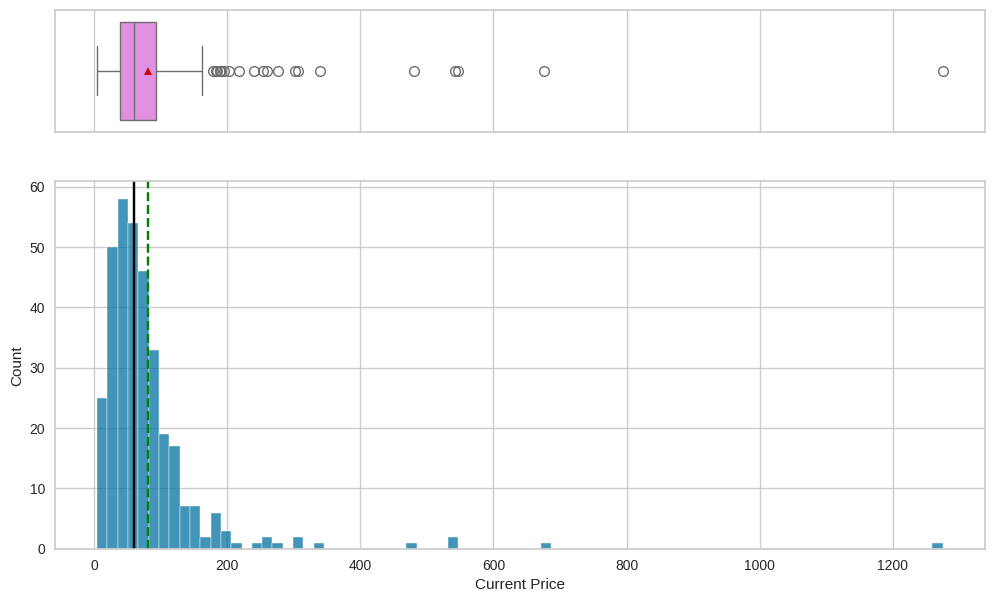

In [ ]:
histogram_boxplot(df, 'Current Price')

- The current stock prices are right skewed with extreme outliers present above the upper whisker.



#### Visualize Price Change

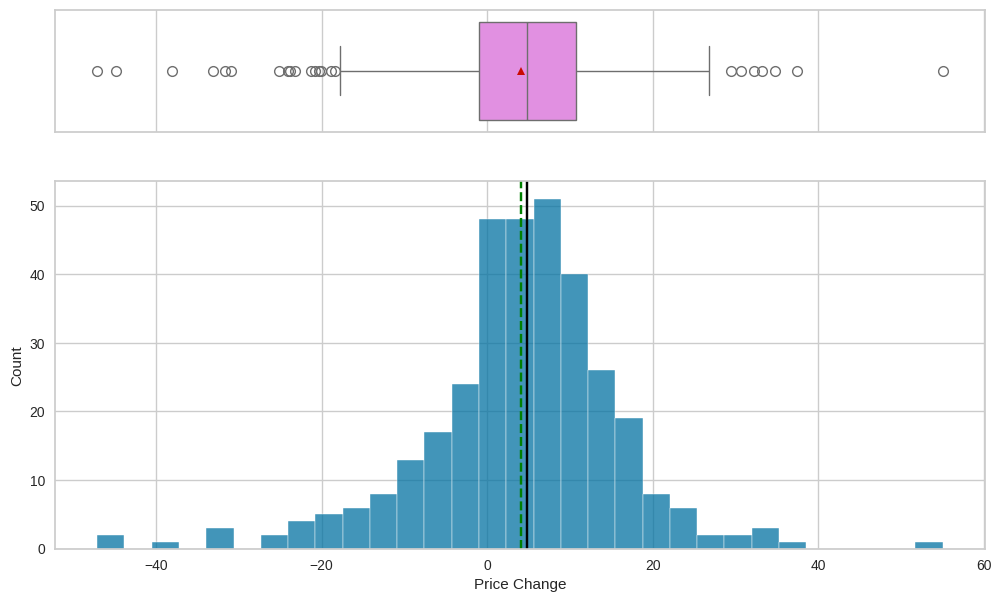

In [ ]:
histogram_boxplot(df, 'Price Change')

- Price Change seems to be relatively normally distributed with a bell-shape like curve.
- There are outliers present outside of the upper and lower whiskers
- The median and average are close in value

#### Visualize Volatility

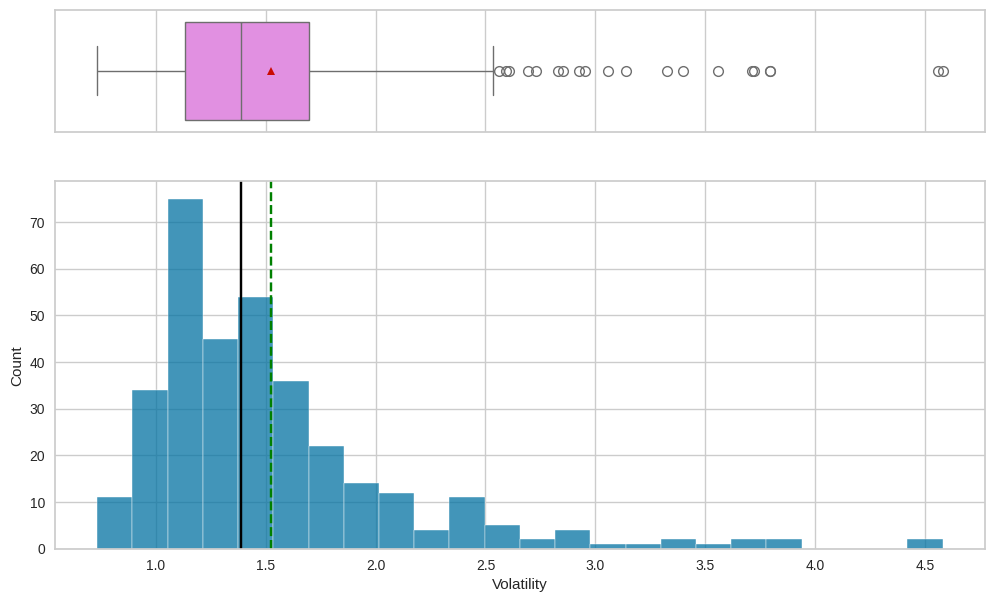

In [ ]:
histogram_boxplot(df, 'Volatility')

- Volatility is right skewed and contains outliers above the upper tail
- The average volatility is higher than the median due to the presence of extreme outliers

 #### Visualize ROE

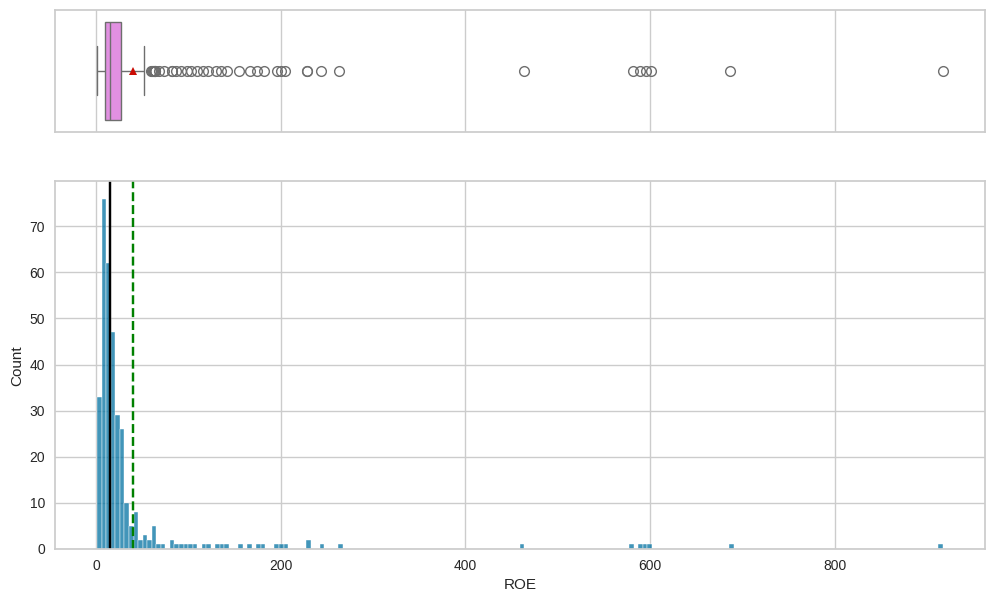

In [ ]:
histogram_boxplot(df, 'ROE')

- ROE is heavily skewed to the right evidenced by the average ROE value being present outside of the IQR.
- There are extreme outliers above the upper whisker

#### Visualize Cash Ratio

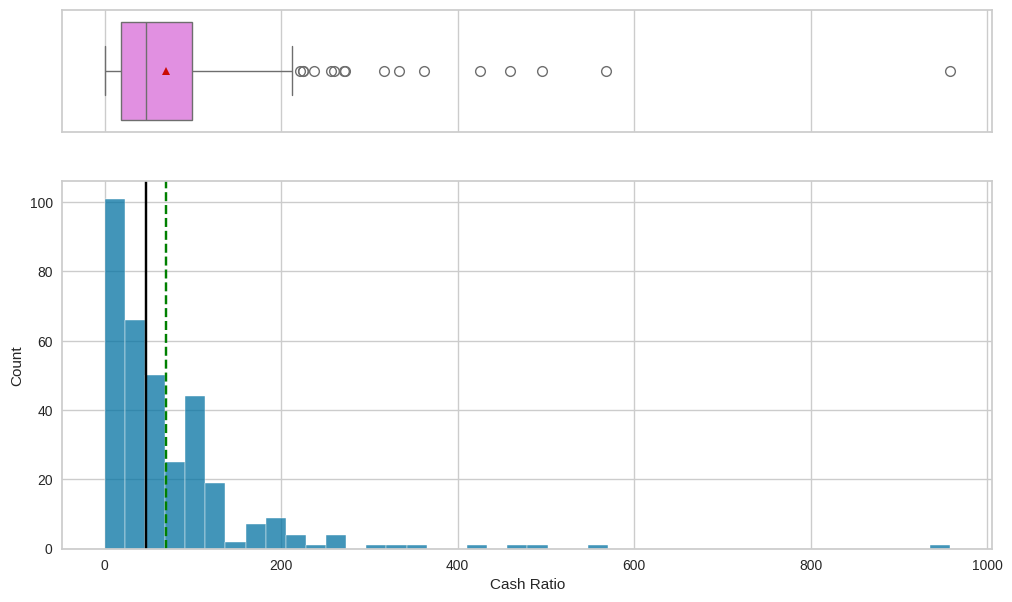

In [ ]:
histogram_boxplot(df, 'Cash Ratio')

- Cash Ratio is right skewed
- There are outliers above the upper whisker.

#### Visualize Net Cash Flow

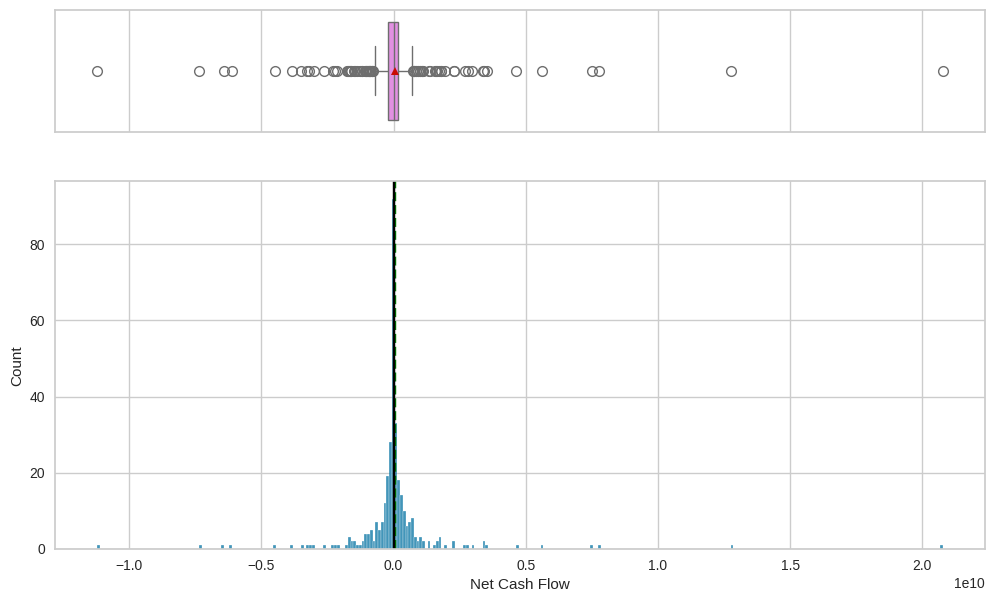

In [ ]:
histogram_boxplot(df, 'Net Cash Flow')

- Cash flow's distribution is relatively normal wth a bell-shape like appearance.
- There are outliers above and below the upper and lower whiskers, repectively.

#### Visualize Net Income

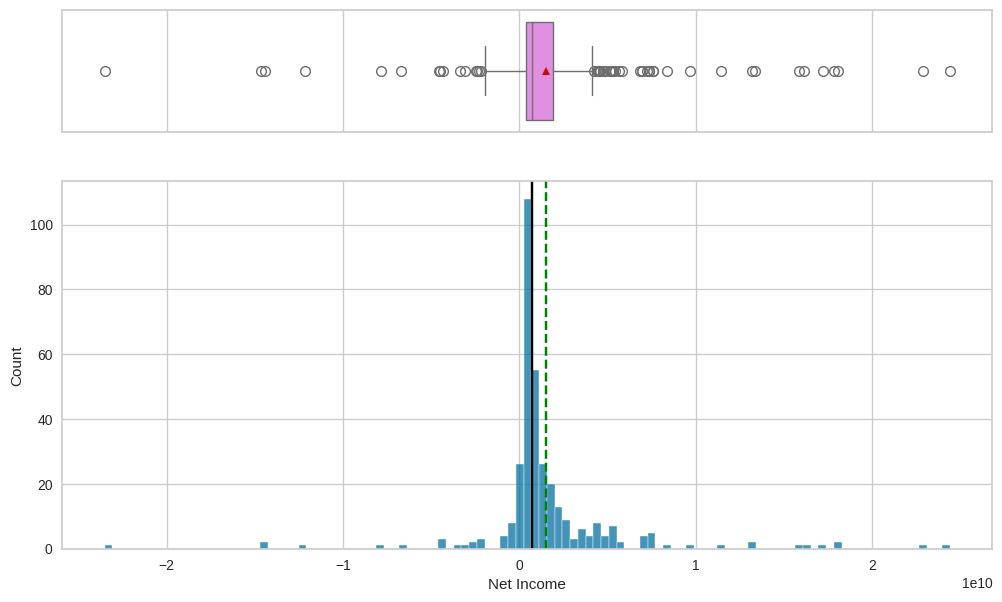

In [ ]:
histogram_boxplot(df, 'Net Income')

- Net Income is slightly skewed to the right.
- There are outliers above and below the whiskers, however most of the outliers are present above the upper whisker.

#### Visualize Earnings Per Share

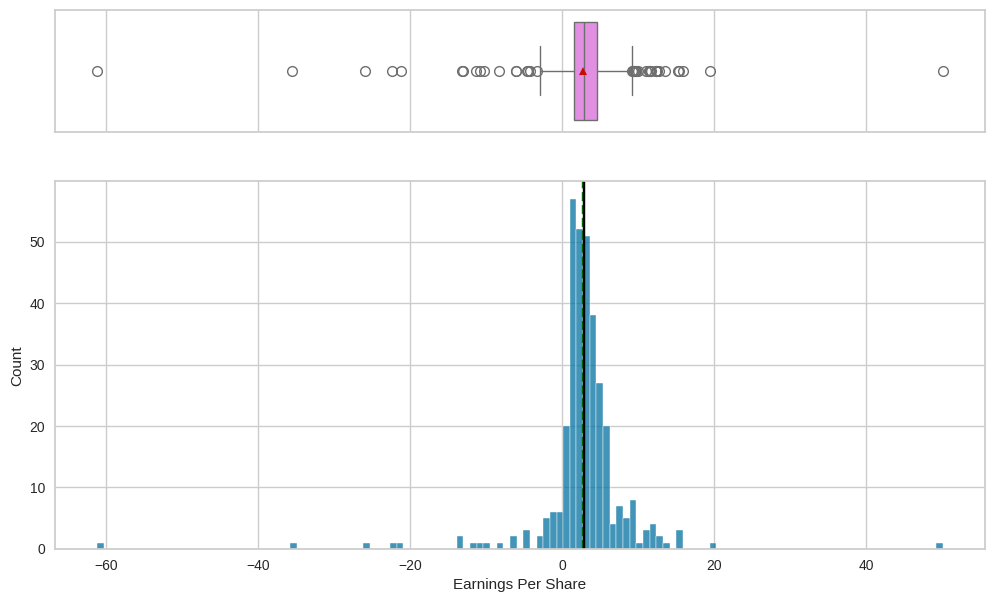

In [ ]:
histogram_boxplot(df, 'Earnings Per Share')

- Earnings per share is relatively normally distributed with a slight left skewe.
- There are outliers outside of both the upper and lower whisker.

#### Visualize Estimated Shares Outstanding

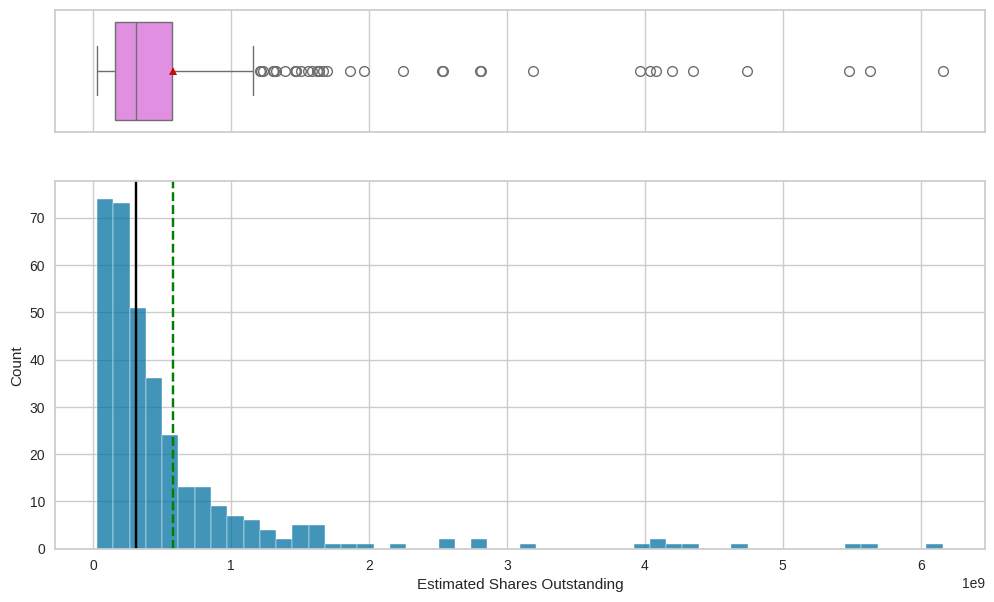

In [ ]:
histogram_boxplot(df, 'Estimated Shares Outstanding')

- Estimated Shares outstanding is heavily skewed to the right
- There are extreme outliers above the upper whisker

#### Visualize P/E Ratio

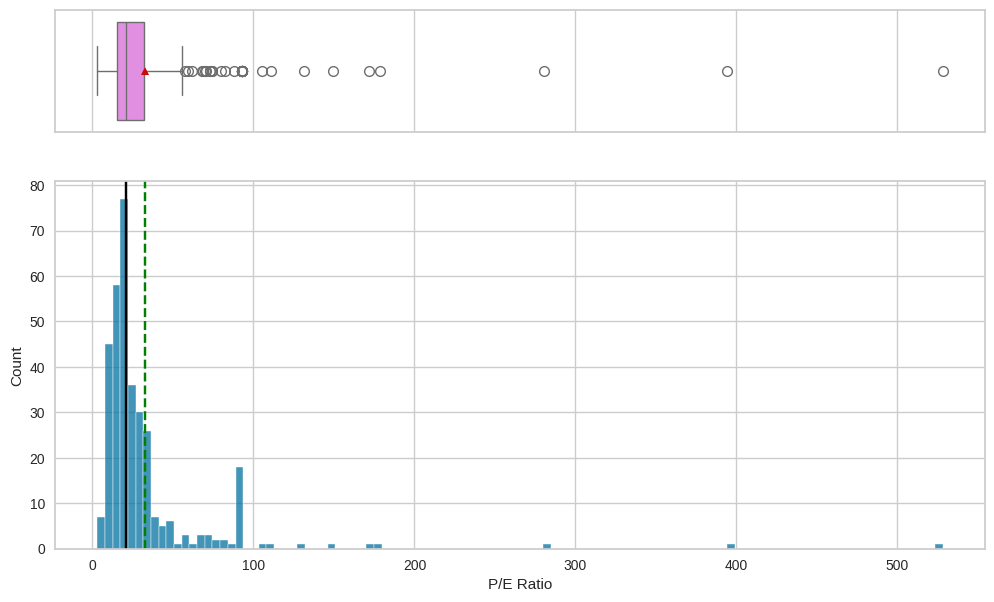

In [ ]:
histogram_boxplot(df, 'P/E Ratio')

-  P/E Ratio is heavily skewed to the right
- There are extreme outliers above the upper whisker

#### Visualize P/B Ratio

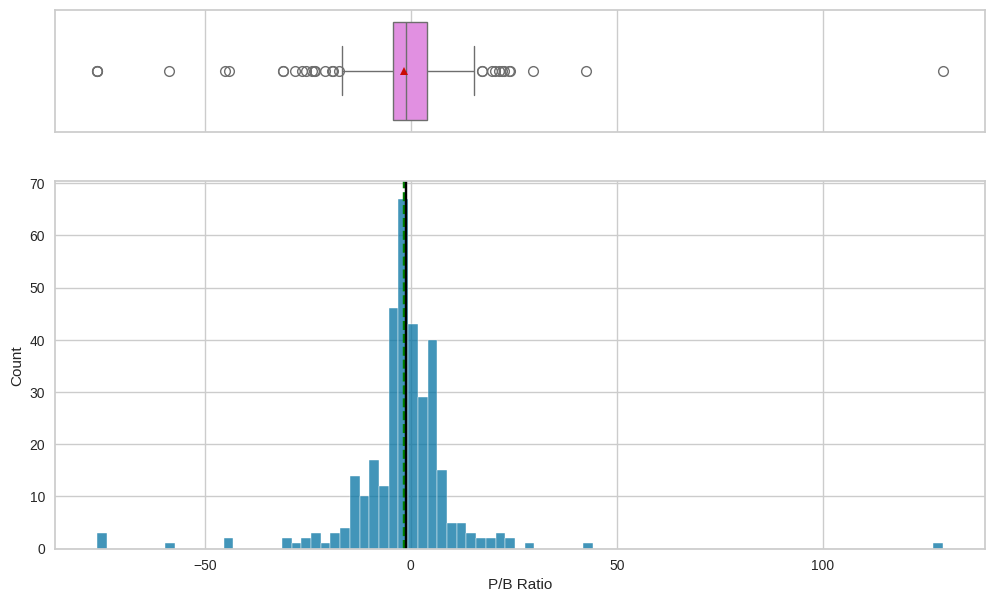

In [ ]:
histogram_boxplot(df, 'P/B Ratio')

- P/B Ratio is distributed relatively normally with outliers above and below the whiskers.


#### Visualize GICS Sector

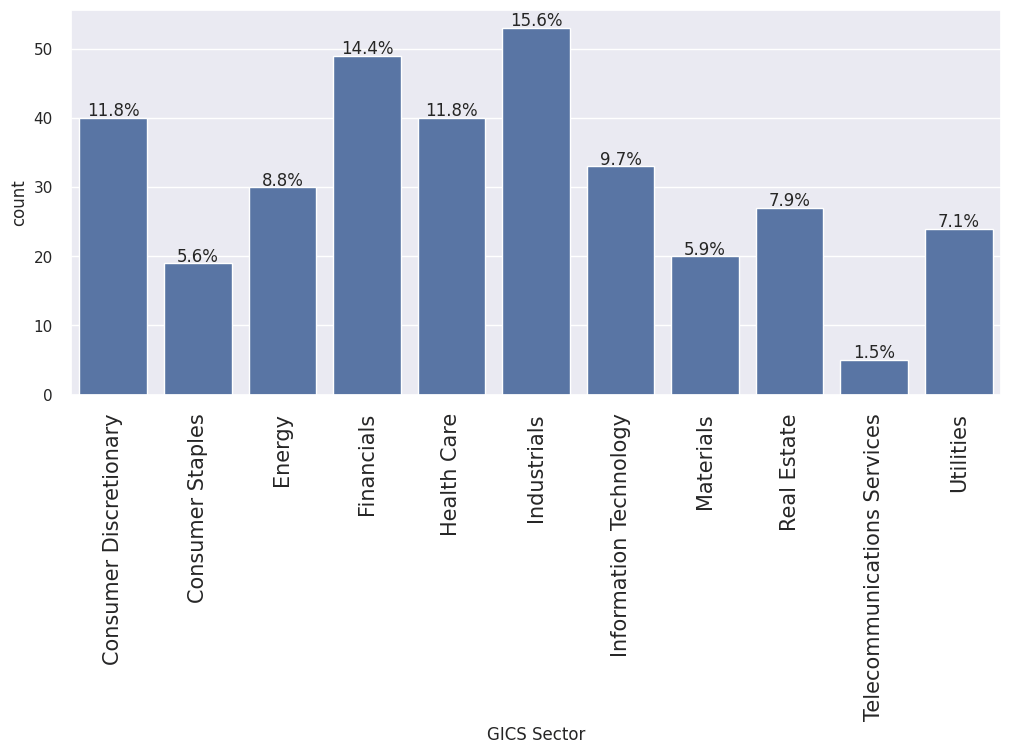

In [220]:
labeled_barplot(df, 'GICS Sector', perc=True)

- The most common Sector is Industrials (15.6%), followed by Financials (14.4%), with Health care and Consumer Discretionary tied for third most prominent sector (11.8%).
- The sectors with the least representation are Telecommunications Services (1.5%), consumer staples (5.6%) and Materials (5.9%).

#### Visualize GICS Sub Industry

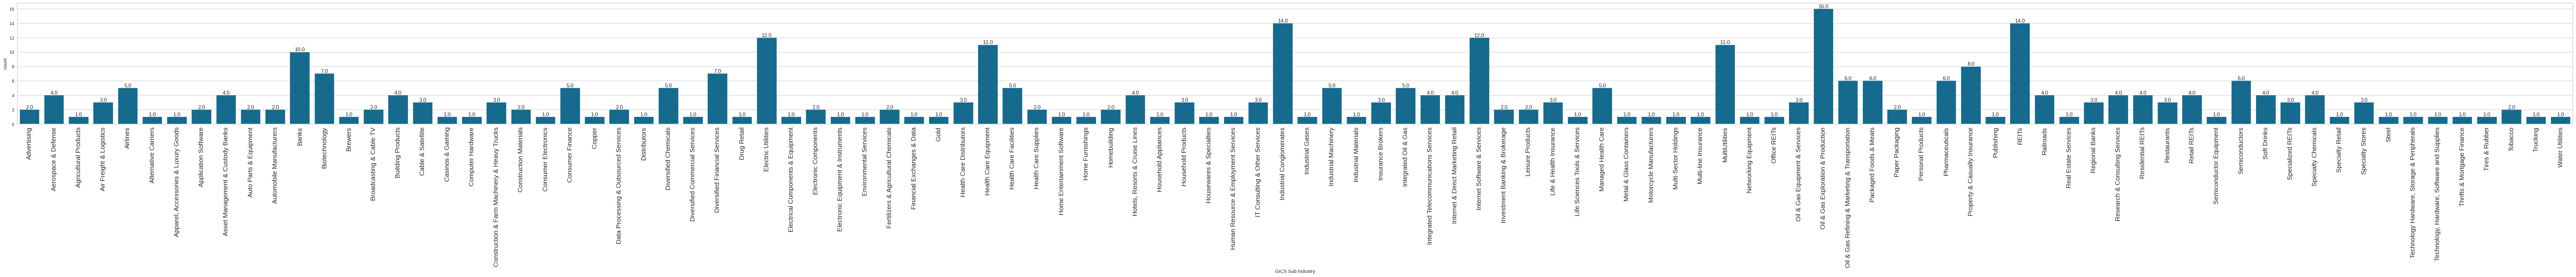

In [ ]:
labeled_barplot(df, 'GICS Sub Industry')

In [ ]:
df['GICS Sub Industry'].value_counts(normalize=True)

GICS Sub Industry
Oil & Gas Exploration & Production                 0.047059
REITs                                              0.041176
Industrial Conglomerates                           0.041176
Electric Utilities                                 0.035294
Internet Software & Services                       0.035294
Health Care Equipment                              0.032353
MultiUtilities                                     0.032353
Banks                                              0.029412
Property & Casualty Insurance                      0.023529
Diversified Financial Services                     0.020588
Biotechnology                                      0.020588
Pharmaceuticals                                    0.017647
Packaged Foods & Meats                             0.017647
Oil & Gas Refining & Marketing & Transportation    0.017647
Semiconductors                                     0.017647
Diversified Chemicals                              0.014706
Consumer Finance      

- The sub industries with the highest representation are Oil & Gas Exploration & Production (4.7%), REITs (4.12%) and Industrial Conglomerates (4.12%)
- There are 42 sub industries all tied for lowest representation at .2%

###Bivariate Analysis

#### Visualize Correlation Between Numeric Variables

In [92]:
#Create a variable with numeric columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()

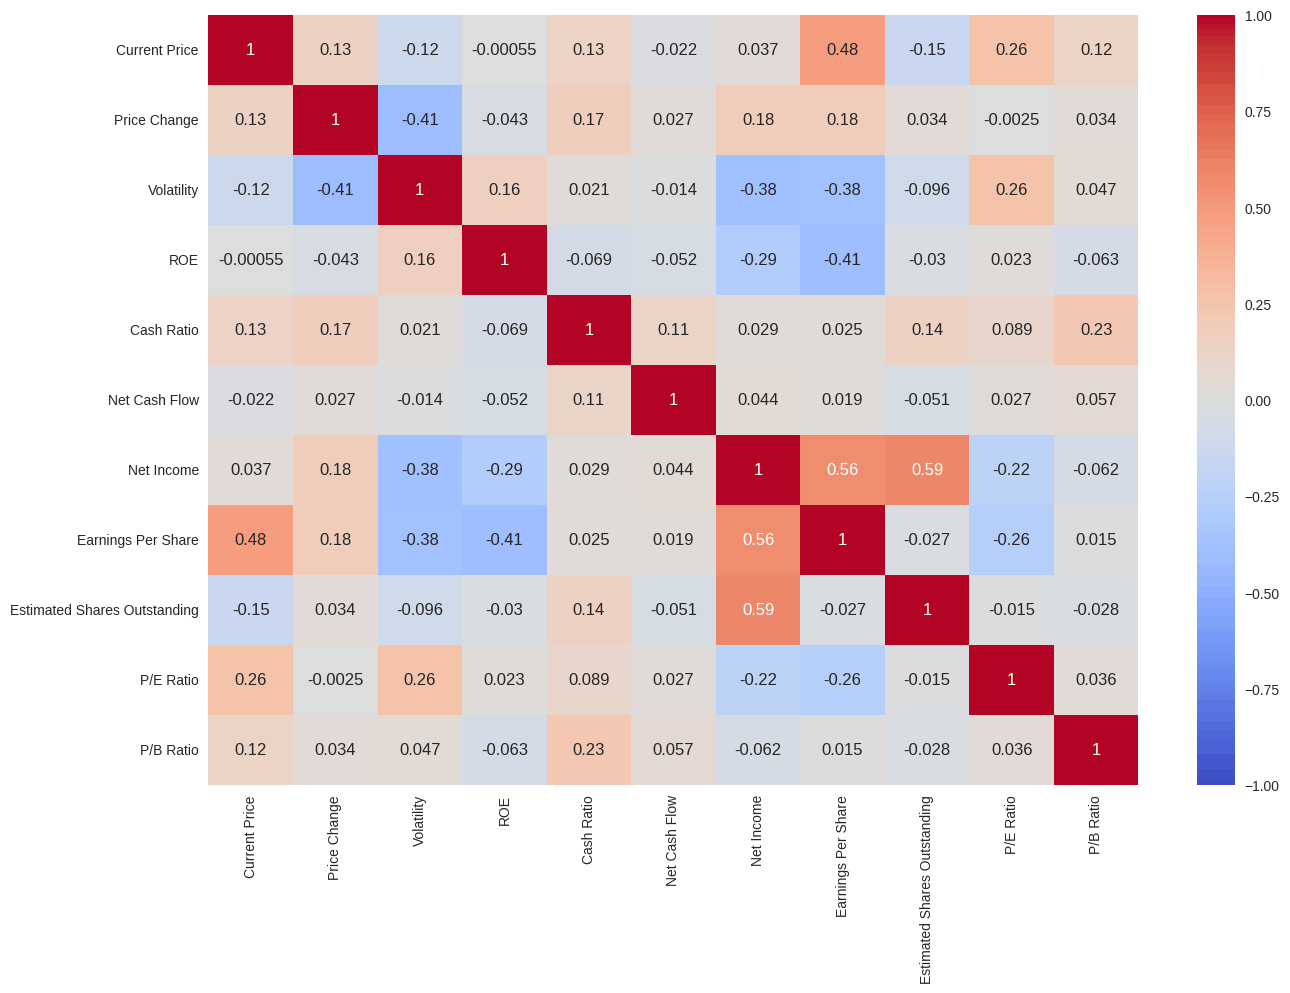

In [ ]:
plt.figure(figsize=(15,10))
sns.heatmap(df[num_cols].corr(), annot= True, vmin=-1, vmax=1, cmap='coolwarm')
plt.show()

- The Numeric Variables don't seem to have very high correlations with eachother.

- The highest positive correlations among variables are Net Income with Estimated Shares Outstanding (0.59), Net Income with Earnings Per Share (0.56), and Current Price with Earnings Per Share (0.48).

- The highest negative correlations among variables are Earnings Per Share with ROE (-0.41),Volatility with Price Change(-0.41), Volatility with Net Income (-0.38), and Volatility with Earnings Per Share (-0.38).
  - While the correlation isn't the strongest, it should be noted among the higher negative correlations observed, Volatility is a common variable.

#### Visualize GICS Sector and Price Change

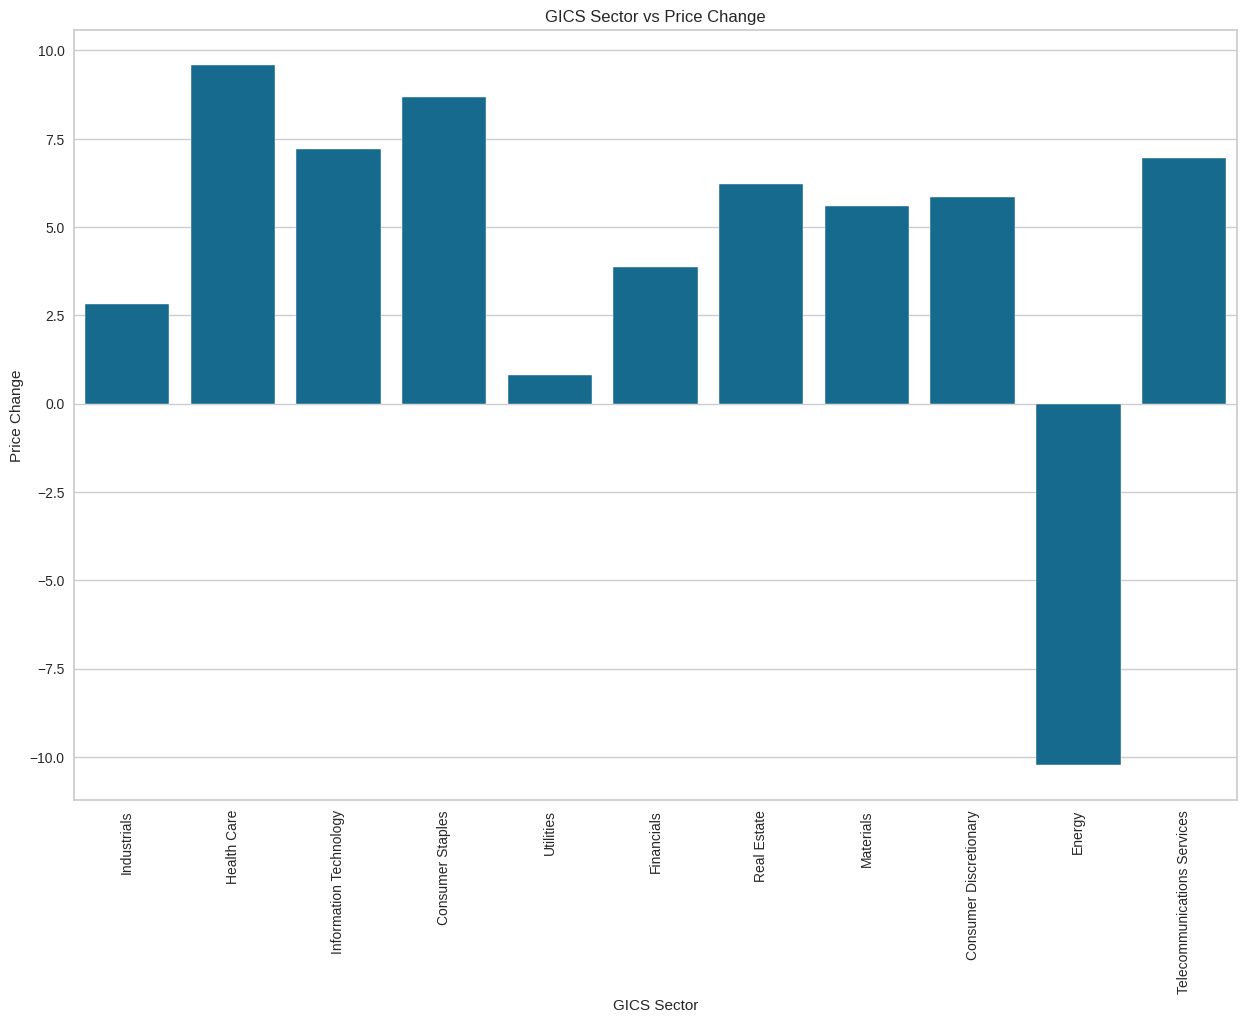

In [ ]:
plt.figure(figsize=(15,10))
sns.barplot(data= df, x='GICS Sector', y= 'Price Change', ci=False)
plt.title('GICS Sector vs Price Change')
plt.xticks(rotation=90)
plt.show()

- The Economic Sector with the highest price increase on average is Health Care, followed by Consumer Staples and Information Technology
- The Economic Sector with the largest price decrease on average is Energy, which is actually the the only sector to have a negative price change

#### Visualize GICS Sector and Cash Ratio

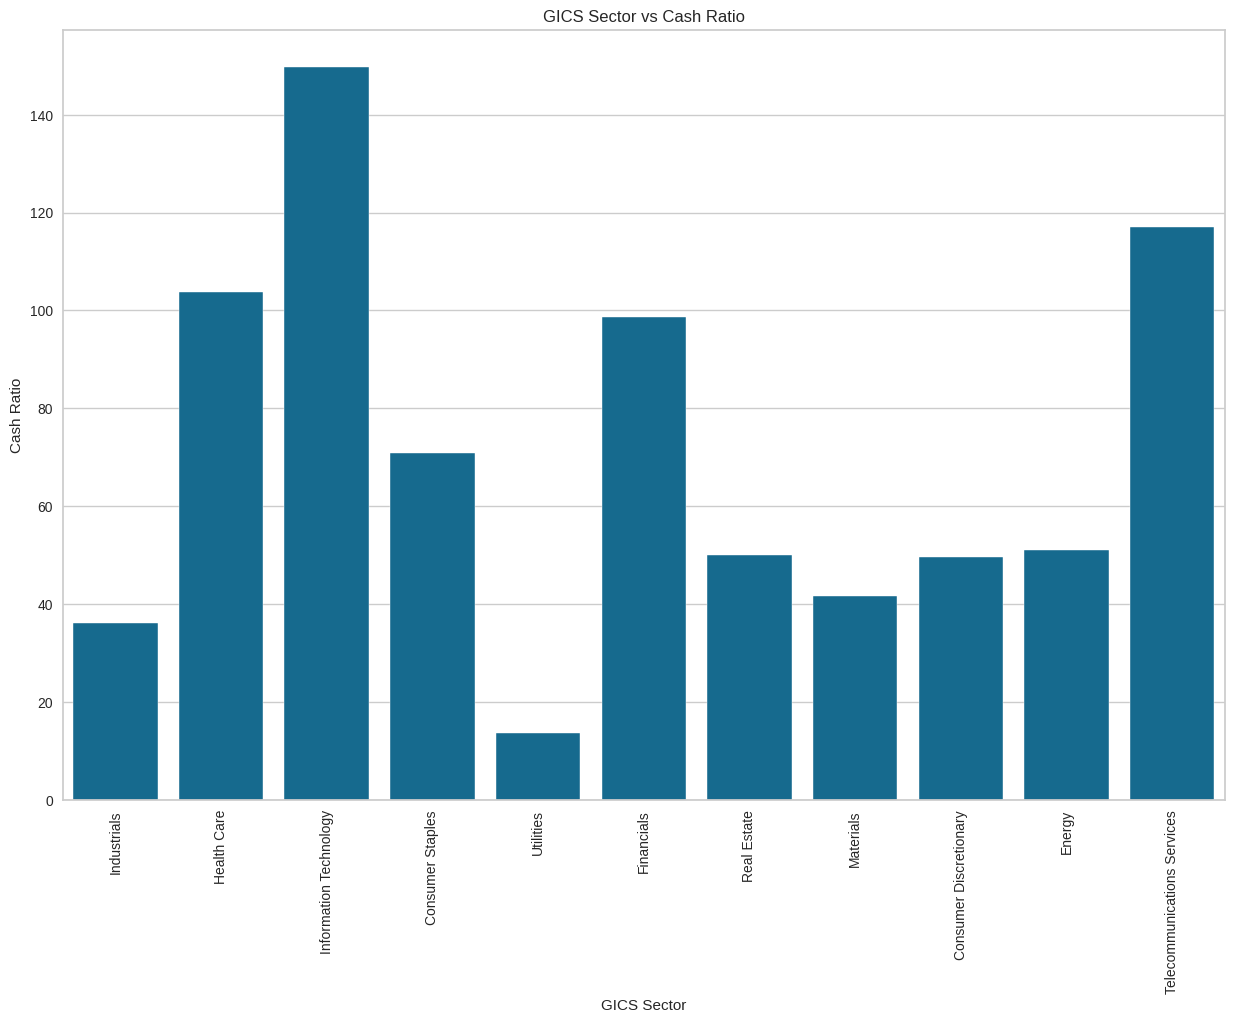

In [ ]:
plt.figure(figsize=(15,10))
sns.barplot(data= df, x='GICS Sector', y= 'Cash Ratio', ci=False)
plt.title('GICS Sector vs Cash Ratio')
plt.xticks(rotation=90)
plt.show()

- The Sectors with the highest cash ratios:
  1. Information Technology
  2. Telecommunications Services
  3. Health Care

- The Sectors with the lowest cash ratios:
  1. Utilities
  2. Industrials
  3. Materials

#### Visualize GICS Sector and P/E Ratio

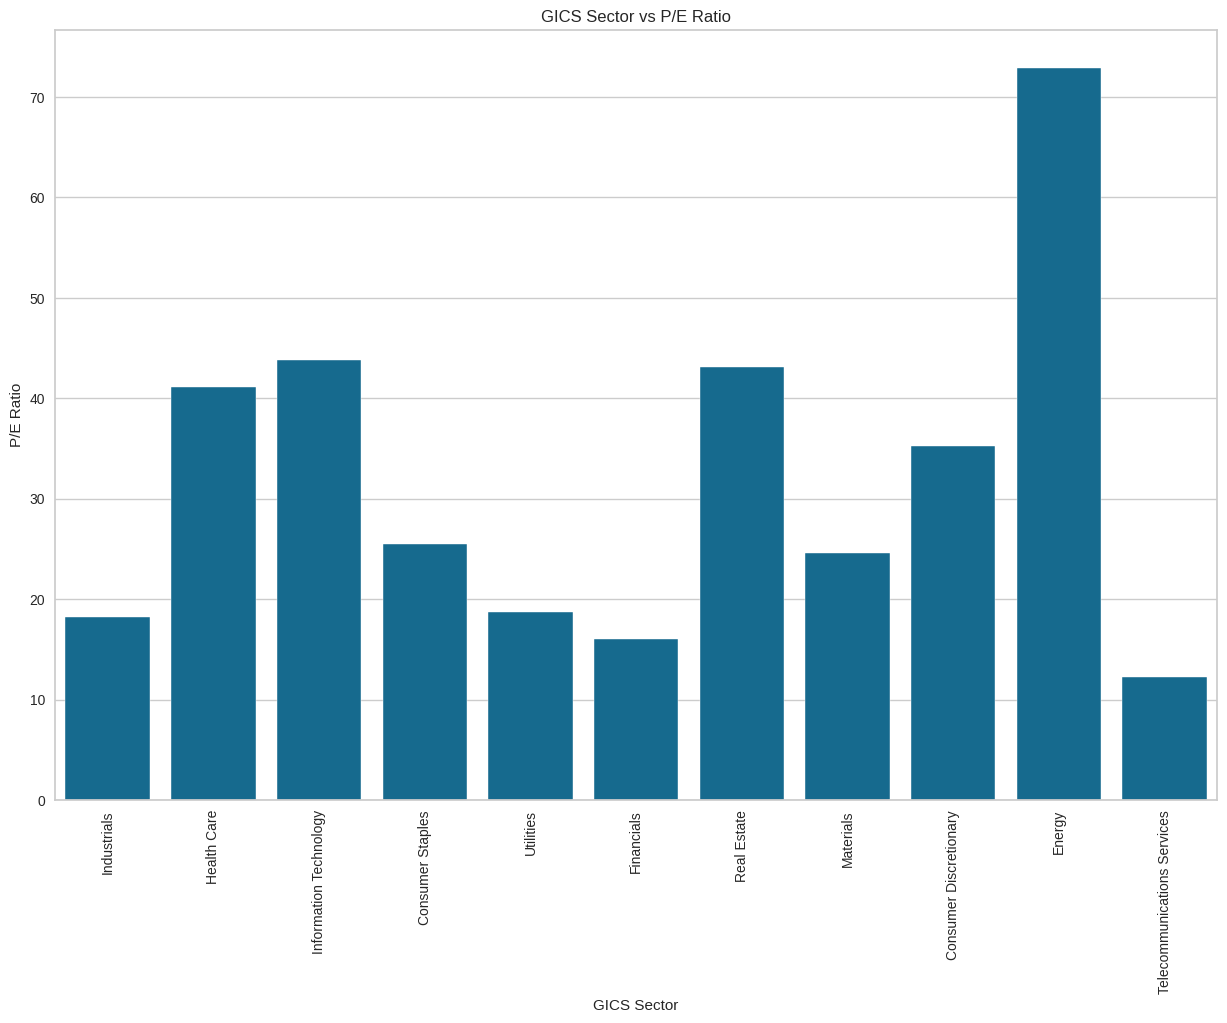

In [ ]:
plt.figure(figsize=(15,10))
sns.barplot(data= df, x='GICS Sector', y= 'P/E Ratio', ci=False)
plt.title('GICS Sector vs P/E Ratio')
plt.xticks(rotation=90)
plt.show()

- The Sectors with the highest P/E Ratios:
  1. Energy
  2. Information Technology
  3. Real Estate

- The Sectors with the lowest P/E Ratios:
  1. Telecommunications Services
  2. Financials
  3. Industrials

#### Visualize GICS Sector and Volatility

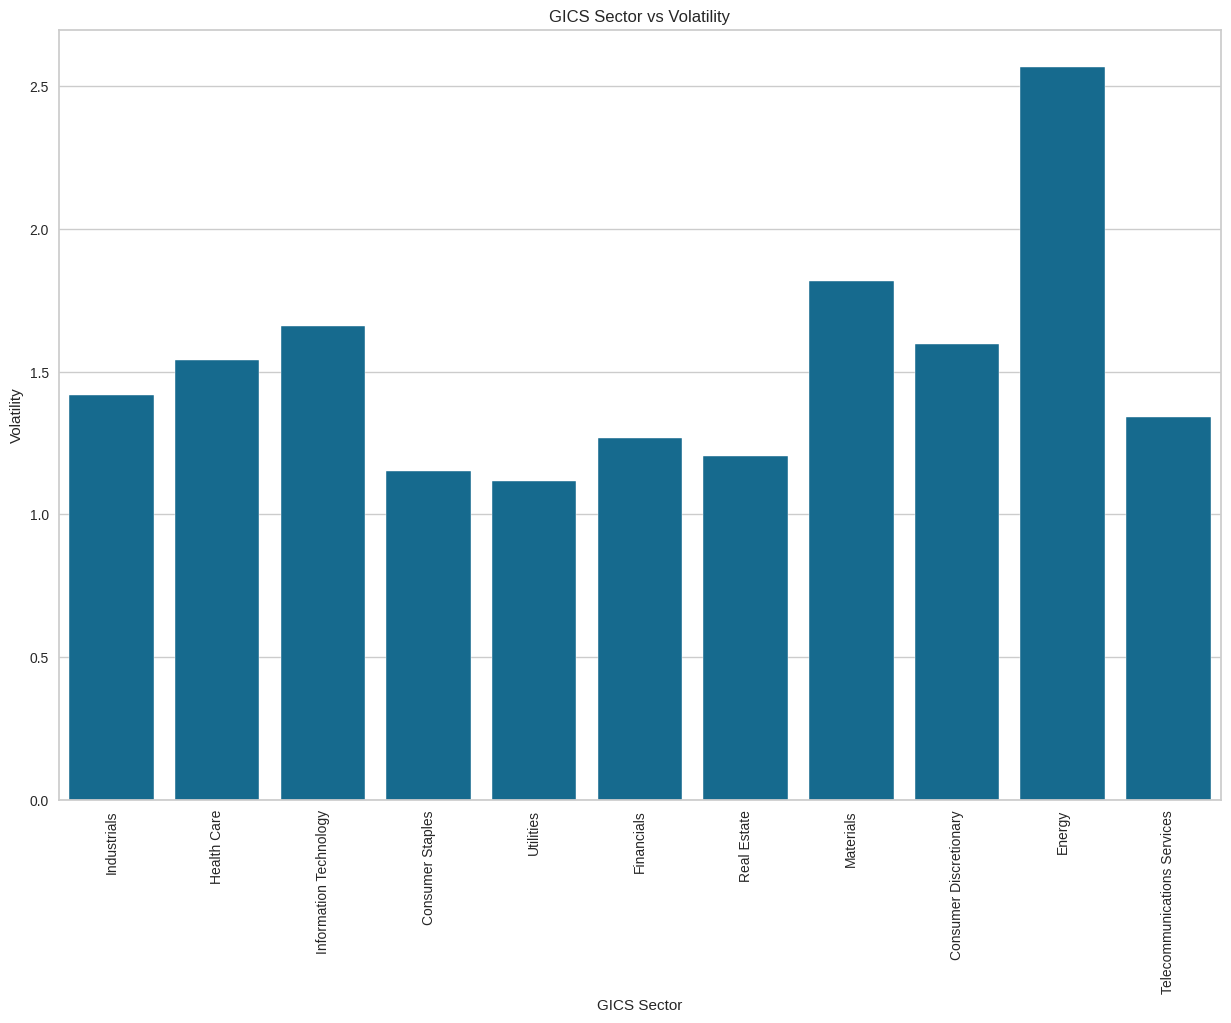

In [ ]:
plt.figure(figsize=(15,10))
sns.barplot(data= df, x='GICS Sector', y= 'Volatility', ci=False)
plt.title('GICS Sector vs Volatility')
plt.xticks(rotation=90)
plt.show()

- The Sectors with the highest Volatility:
  1. Energy
  2. Materials
  3. Information Technology

- The Sectors with the lowest Volatility:
  1. Utilities
  2. Consumer Staples
  3. Real Estate

####Pair Plot for Numeric Variables


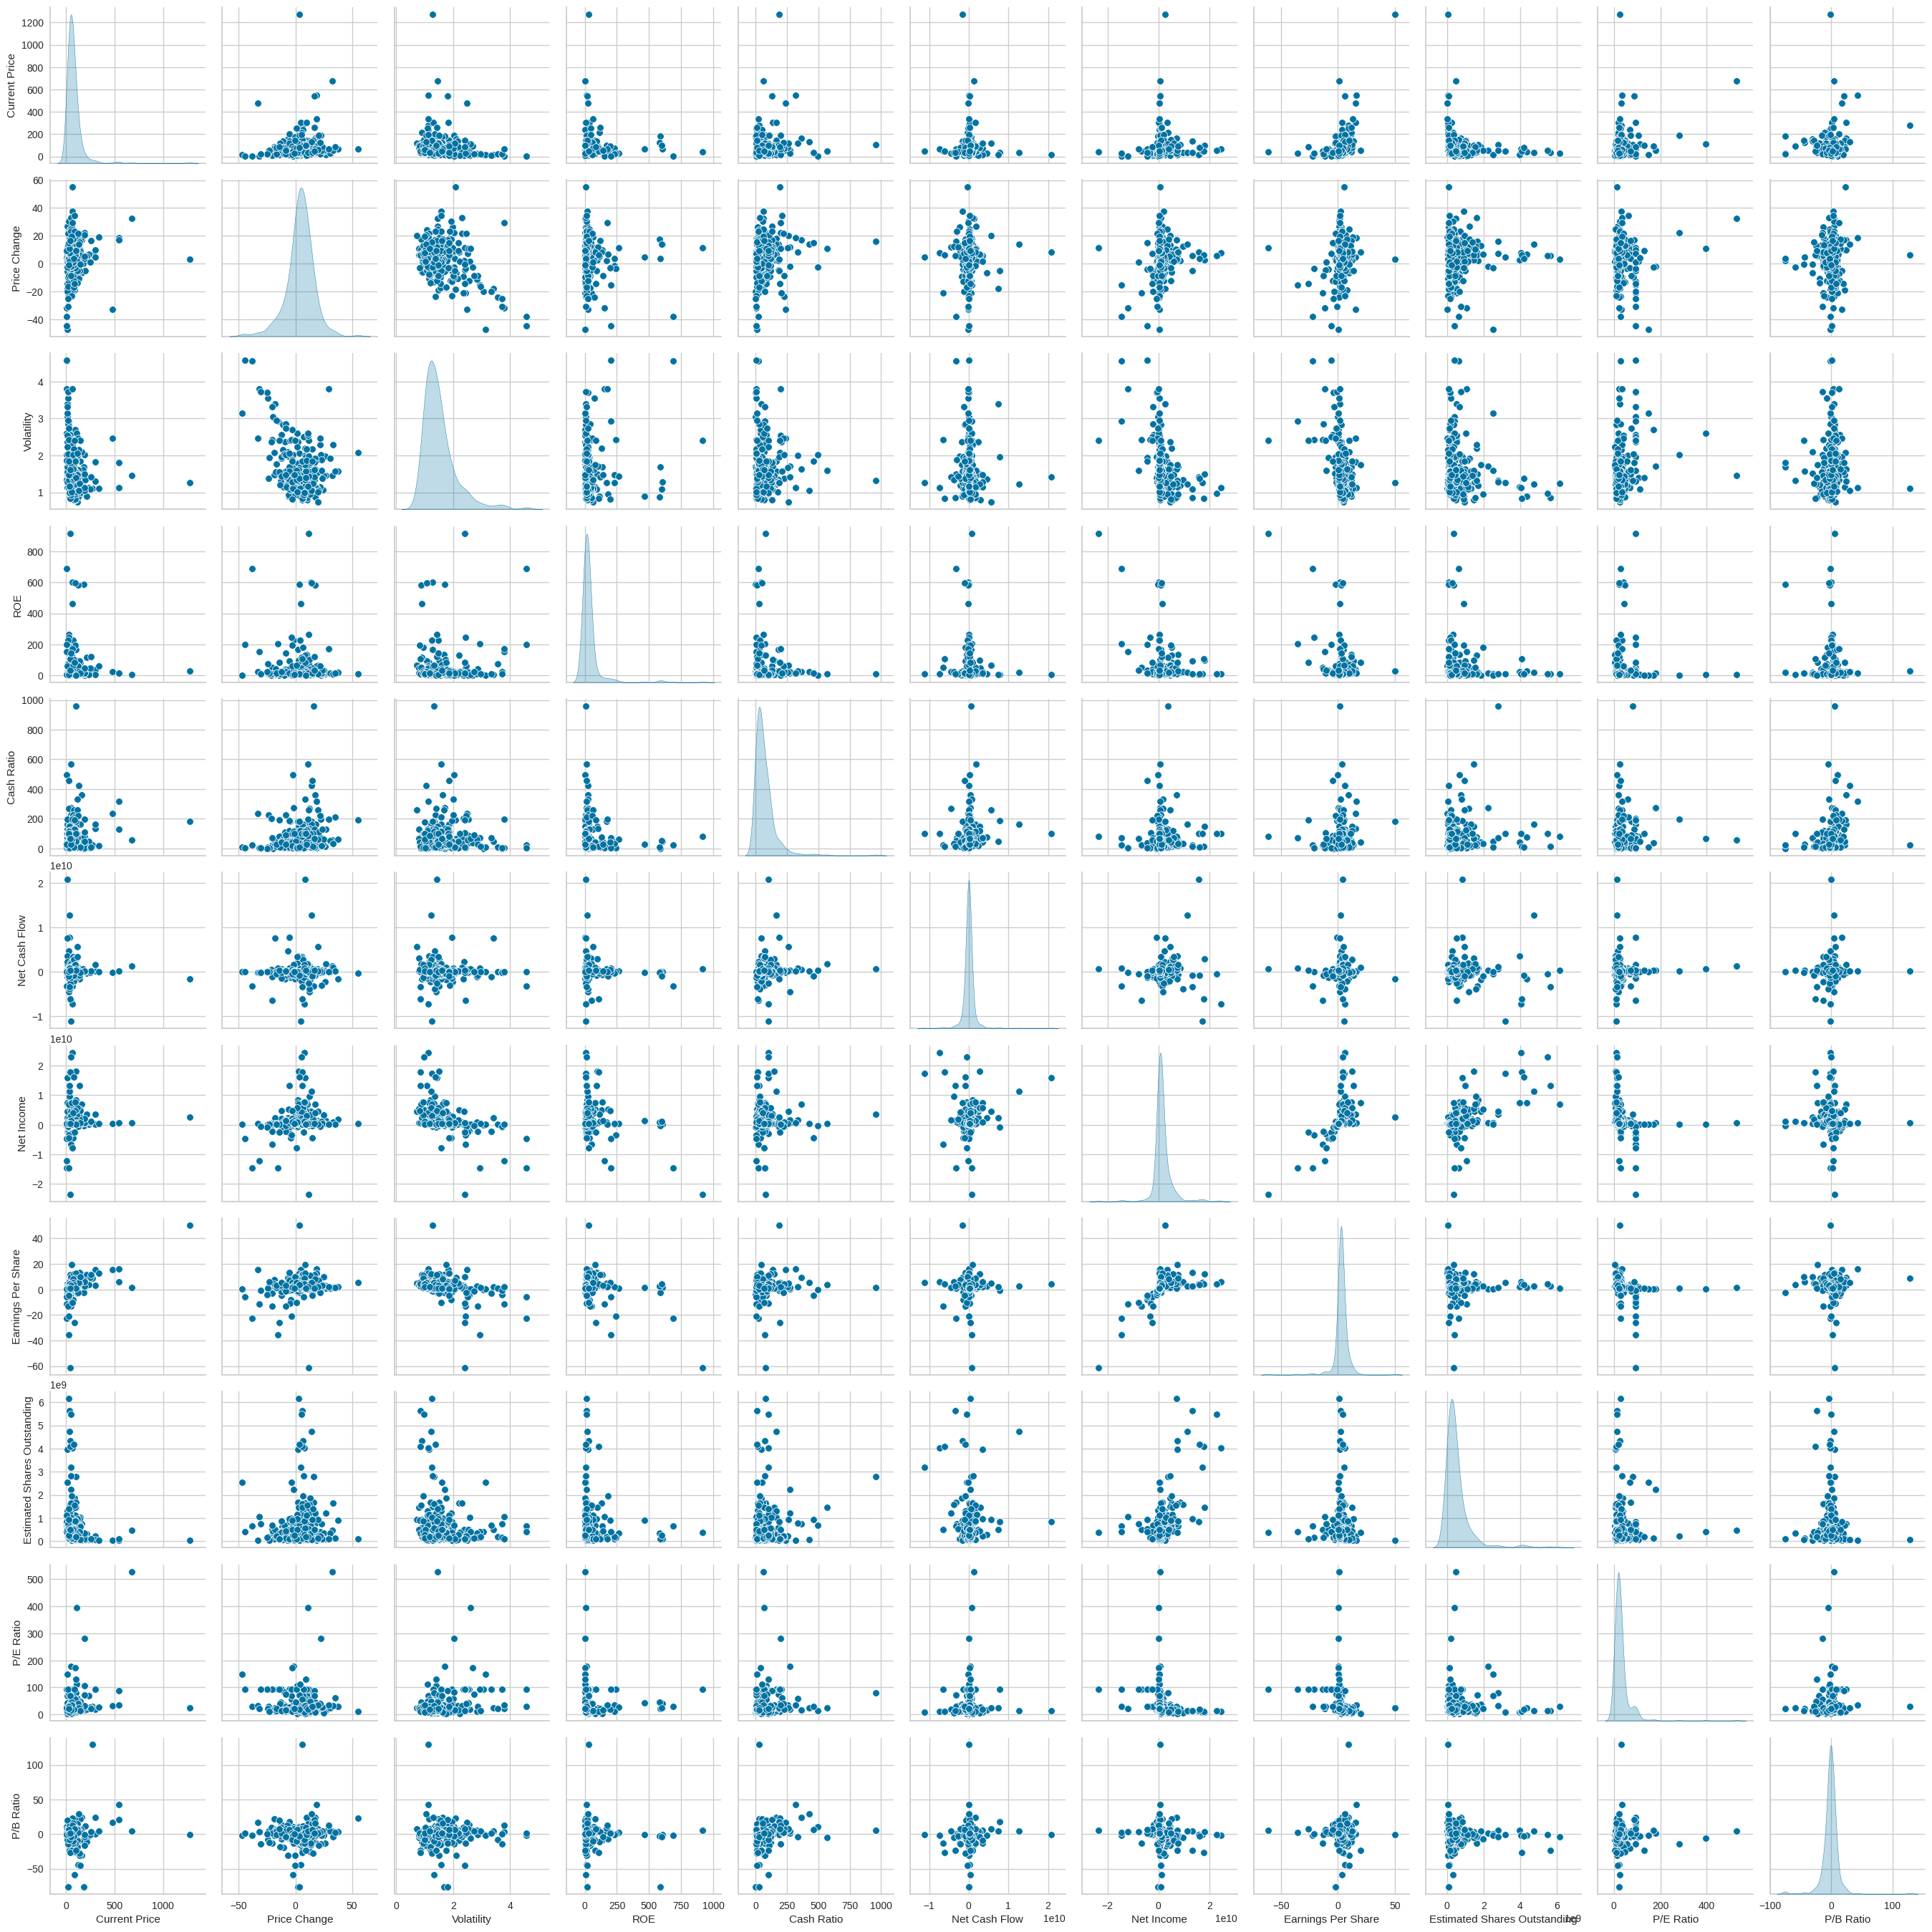

In [ ]:
sns.pairplot(data=df[num_cols], diag_kind='kde')

## Data Preprocessing



**Outlier Check**

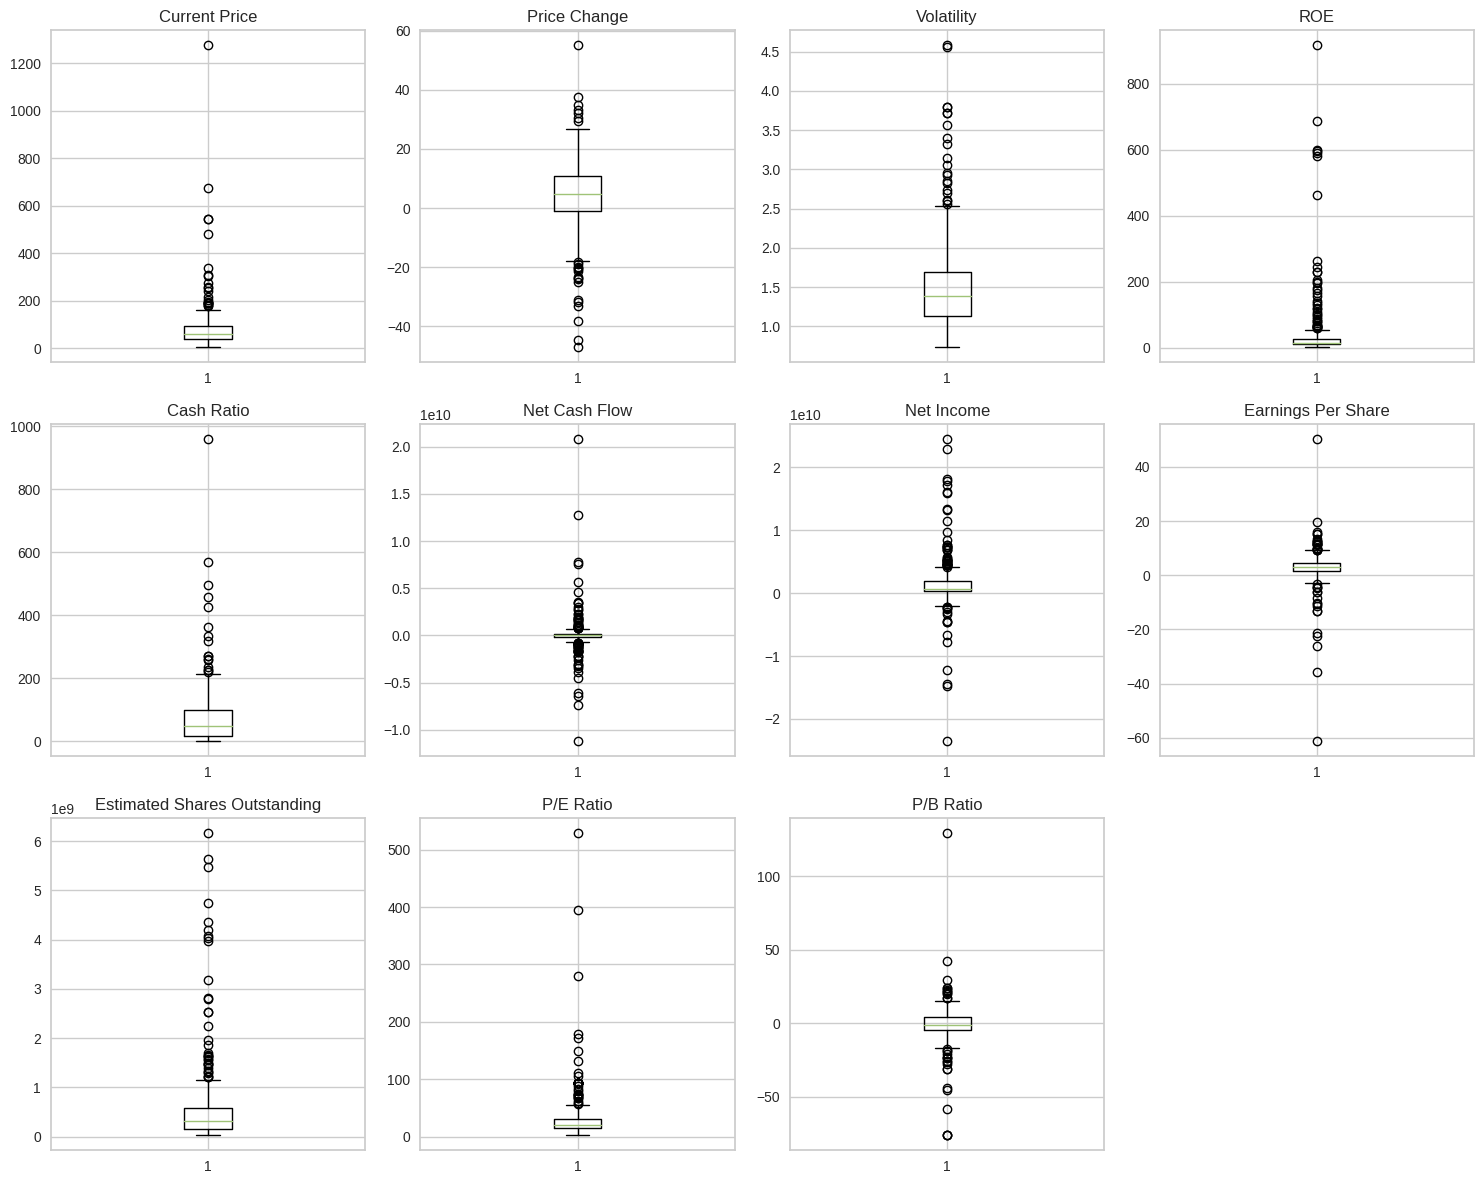

In [ ]:
#Check for outliers
plt.figure(figsize=(15, 12))



for i, variable in enumerate(num_cols):
    plt.subplot(3, 4, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

- There are many outliers in the data frame, however we will leave these as is due to the values likely being true.
  - With so many companies in different Sectors and sub industries, the variability between each company is expected.

**Scaling the Data Set**

In [ ]:
#scaling the data before clustering
scaler= StandardScaler()
subset = df[num_cols].copy()
subset_scaled = scaler.fit_transform(subset)

In [ ]:
#create a new dataframe from the scaled data
subset_scaled_df = pd.DataFrame(subset_scaled, columns= subset.columns)

## K-means Clustering

In [ ]:
#Create a copy of the scaled data frame to be used in k-means clustering
k_means_df = subset_scaled_df.copy()

Number of clusters: 1 	Average Distorition: 2.5425069919221697
Number of clusters: 2 	Average Distorition: 2.382318498894466
Number of clusters: 3 	Average Distorition: 2.2692367155390745
Number of clusters: 4 	Average Distorition: 2.1745559827866363
Number of clusters: 5 	Average Distorition: 2.128799332840716
Number of clusters: 6 	Average Distorition: 2.080400099226289
Number of clusters: 7 	Average Distorition: 2.0289794220177395
Number of clusters: 8 	Average Distorition: 1.964144163389972
Number of clusters: 9 	Average Distorition: 1.9221492045198068
Number of clusters: 10 	Average Distorition: 1.8513913649973124
Number of clusters: 11 	Average Distorition: 1.8024134734578485
Number of clusters: 12 	Average Distorition: 1.7900931879652673
Number of clusters: 13 	Average Distorition: 1.7417609203336912
Number of clusters: 14 	Average Distorition: 1.673559857259703
Number of clusters: 15 	Average Distorition: 1.6651216575252537
Number of clusters: 16 	Average Distorition: 1.6244100

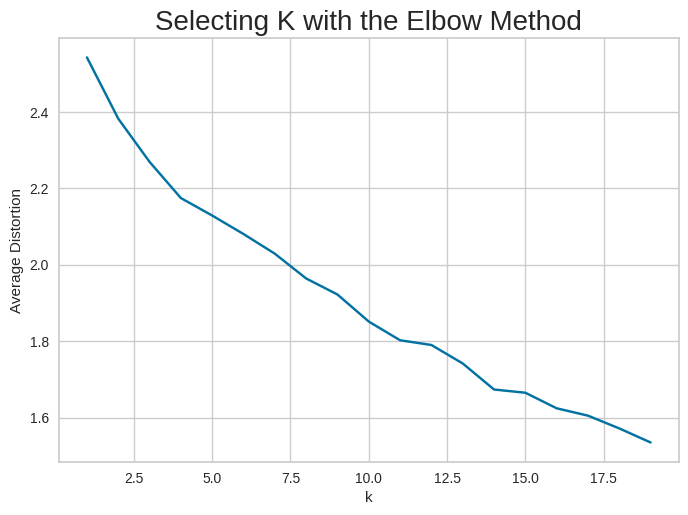

CPU times: user 3.01 s, sys: 130 ms, total: 3.14 s
Wall time: 2.74 s


In [ ]:
%%time

clusters = range(1,20)
meanDistortions = []

for k in clusters:
  model= KMeans(n_clusters=k, random_state=1)
  model.fit(k_means_df)
  prediction = model.predict(k_means_df)
  distortion= (
      sum(np.min(cdist(k_means_df, model.cluster_centers_, 'euclidean'), axis=1))
      / k_means_df.shape[0]
  )

  meanDistortions.append(distortion)

  print("Number of clusters:", k, "\tAverage Distorition:", distortion)

plt.plot(clusters, meanDistortions, "bx-")
plt.xlabel("k")
plt.ylabel("Average Distortion")
plt.title("Selecting K with the Elbow Method", fontsize=20)
plt.show()

**The Appropiate value of K from the elbow curve seems to be 3, 8, or 11**

- We will further explore these K-Values and compute silhouette scores to see which value of k would be best.

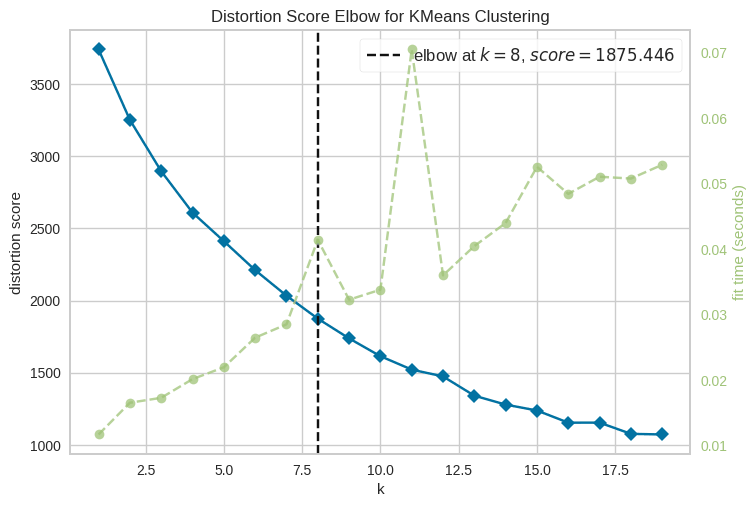

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
model = KMeans(random_state=1)
visualizer = KElbowVisualizer(model, k=(1, 20), timings=True)
visualizer.fit(k_means_df)  # fit the data to the visualizer
visualizer.show()  # finalize and render figure

- The optimal K seems to be 8 in comparison to the other K-Values

###Silhouette Scores

for n_clusters = 2, the silhouette score is 0.43969639509980457
for n_clusters = 3, the silhouette score is 0.4644405674779404
for n_clusters = 4, the silhouette score is 0.4577225970476733
for n_clusters = 5, the silhouette score is 0.43228336443659804
for n_clusters = 6, the silhouette score is 0.4005422737213617
for n_clusters = 7, the silhouette score is 0.3976335364987305
for n_clusters = 8, the silhouette score is 0.40278401969450467
for n_clusters = 9, the silhouette score is 0.3778585981433699
for n_clusters = 10, the silhouette score is 0.13458938329968687
for n_clusters = 11, the silhouette score is 0.1421832155528444
for n_clusters = 12, the silhouette score is 0.2044669621527429
for n_clusters = 13, the silhouette score is 0.23424874810104204
for n_clusters = 14, the silhouette score is 0.12102526472829901
for n_clusters = 15, the silhouette score is 0.15857943020213497
for n_clusters = 16, the silhouette score is 0.13760795993463953
for n_clusters = 17, the silhouette scor

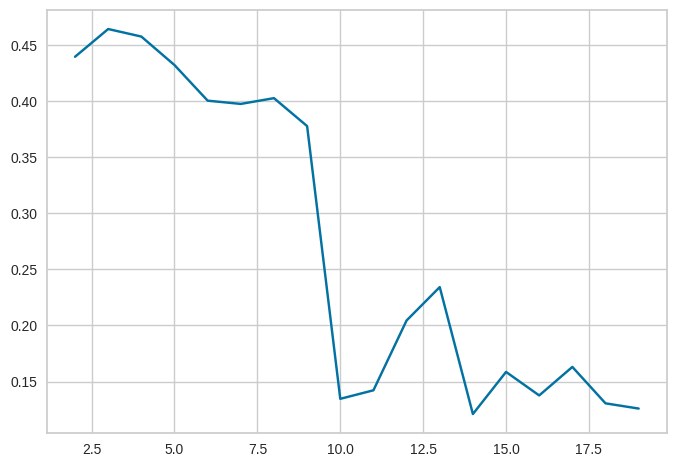

CPU times: user 5.07 s, sys: 1.58 s, total: 6.65 s
Wall time: 4.5 s


In [ ]:
%%time
sil_score= []
cluster_list = range(2,20)
for n_clusters in cluster_list:
  clusterer = KMeans( n_clusters=n_clusters, random_state=1)
  preds= clusterer.fit_predict(k_means_df)
  score= silhouette_score(k_means_df, preds)
  sil_score.append(score)
  print("for n_clusters = {}, the silhouette score is {}".format(n_clusters, score))

plt.plot(cluster_list, sil_score)
plt.show()

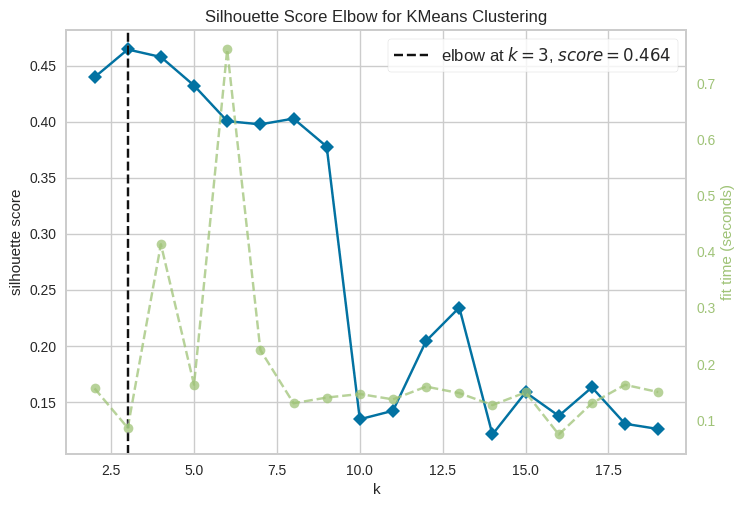

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [ ]:
model = KMeans(random_state=1)
visualizer = KElbowVisualizer(model, k=(2, 20), metric="silhouette", timings=True)
visualizer.fit(k_means_df)
visualizer.show()

From the silhouette scores the highest value is when k=3, however k=8, while lower seems to be a good choice as well.

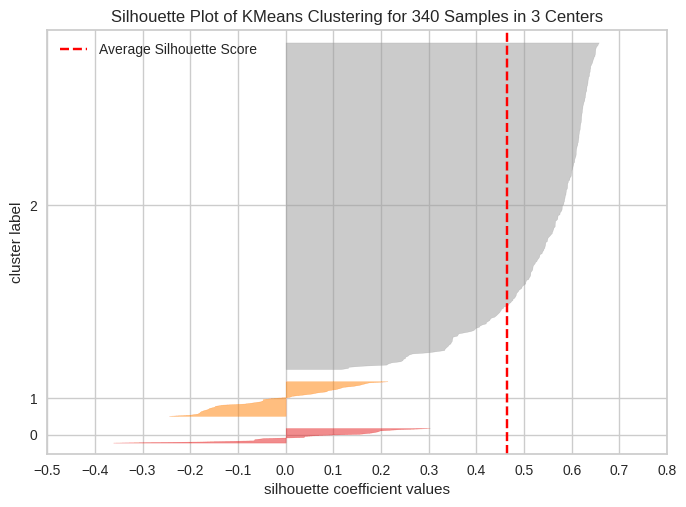

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 340 Samples in 3 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
# finding optimal no. of clusters with silhouette coefficients
visualizer = SilhouetteVisualizer(KMeans(3, random_state=1))
visualizer.fit(k_means_df)
visualizer.show()

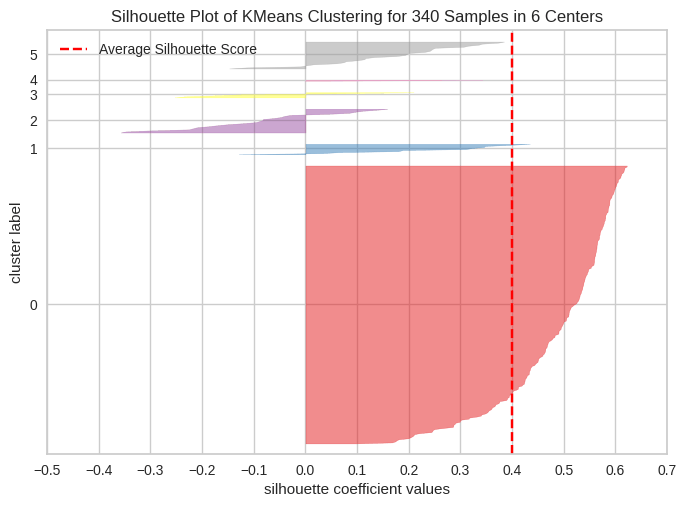

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 340 Samples in 6 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
# finding optimal no. of clusters with silhouette coefficients
visualizer = SilhouetteVisualizer(KMeans(6, random_state=1))
visualizer.fit(k_means_df)
visualizer.show()

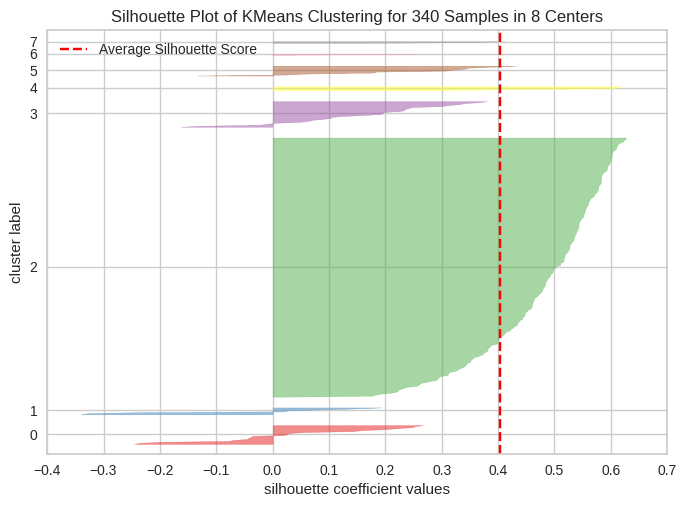

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 340 Samples in 8 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
# finding optimal no. of clusters with silhouette coefficients
visualizer = SilhouetteVisualizer(KMeans(8, random_state=1))
visualizer.fit(k_means_df)
visualizer.show()

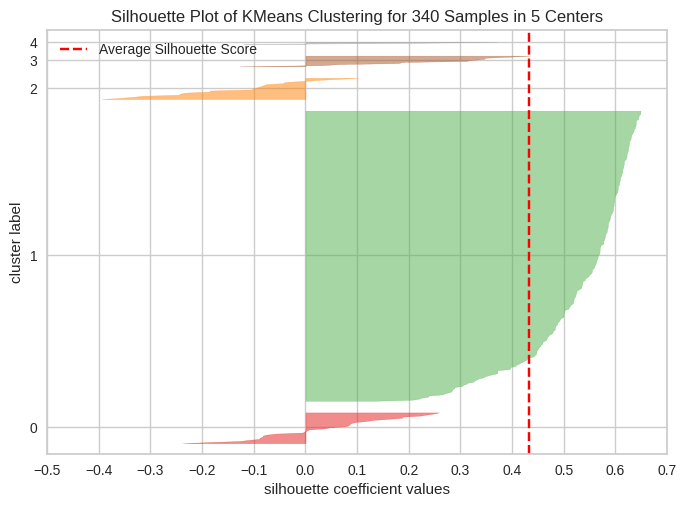

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 340 Samples in 5 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [ ]:
# finding optimal no. of clusters with silhouette coefficients
visualizer = SilhouetteVisualizer(KMeans(5, random_state=1))
visualizer.fit(k_means_df)
visualizer.show()

###Creating Final Model

***After visualizing the silhouette scores for a few different k-values: k=3 is looking very good, however k=8 has less density per cluster in the negative range of Silhouette scores**

**We will proceed with K=8 as the final model**


In [ ]:
#set and fit the final model

kmeans = KMeans(n_clusters=8, random_state=1)
kmeans.fit(subset_scaled_df)

KMeans(random_state=1)

In [ ]:
#Create a copy of original data frame to apply cluster labels to
dfK= df.copy()

#adding kmeans cluster labels to the original and scaled dataframes
k_means_df['KM_segments']=  kmeans.labels_

dfK['KM_segments']= kmeans.labels_

###Cluster Profiling

In [93]:
#Add KM_segments to the num_cols variable
num_cols.append('KM_segments')


In [96]:
#Check to see that it was added correctly
num_cols

['Current Price',
 'Price Change',
 'Volatility',
 'ROE',
 'Cash Ratio',
 'Net Cash Flow',
 'Net Income',
 'Earnings Per Share',
 'Estimated Shares Outstanding',
 'P/E Ratio',
 'P/B Ratio',
 'KM_segments']

In [67]:
#Grouping the data frame by cluster labels
km_cluster_profile = dfK[num_cols].groupby('KM_segments').mean()

In [69]:
#Grouping Companies by the cluster label
km_cluster_profile['count_in_each_segment'] = (dfK.groupby('KM_segments')['Security'].count().values)

In [71]:
#display the cluster profiles
km_cluster_profile.style.highlight_max(color='lightgreen', axis=0)

,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio,count_in_each_segment
KM_segments,,,,,,,,,,,,
0,80.152167,14.571437,1.829679,28.100000,321.850000,625929050.000000,942050500.000000,2.010500,790456335.265000,45.067457,8.307945,20
1,508.534992,5.732177,1.504640,27.250000,150.875000,37895875.000000,1116994125.000000,15.965000,75654420.935000,43.727459,29.581664,8
2,71.100057,4.970680,1.372796,24.988636,51.087121,87930727.272727,1579775988.636364,3.688466,435677482.318371,23.232454,-3.350613,264
3,34.231808,-15.515565,2.832069,48.037037,47.740741,-128651518.518519,-2444318518.518518,-6.284444,503031539.057037,75.627265,1.655990,27
4,108.304002,10.737770,1.165694,566.200000,26.600000,-278760000.000000,687180000.000000,1.548000,349607057.720000,34.898915,-16.851358,5
5,50.517273,5.747586,1.130399,31.090909,75.909091,-1072272727.272727,14833090909.090910,4.154545,4298826628.727273,14.803577,-4.552119,11
6,24.485001,-13.351992,3.482611,802.000000,51.000000,-1292500000.000000,-19106500000.000000,-41.815000,519573983.250000,60.748608,1.565141,2
7,327.006671,21.917380,2.029752,4.000000,106.000000,698240666.666667,287547000.000000,0.750000,366763235.300000,400.989188,-5.322376,3


In [73]:
# let's see the names of the countries in each cluster
for cl in dfK["KM_segments"].unique():
    print("In cluster {}, the following companies are present:".format(cl))
    print(dfK[dfK["KM_segments"] == cl]["Security"].unique())
    print()

In cluster 2, the following companies are present:
['American Airlines Group' 'AbbVie' 'Abbott Laboratories'
 'Archer-Daniels-Midland Co' 'Ameren Corp' 'American Electric Power'
 'AFLAC Inc' 'American International Group, Inc.'
 'Apartment Investment & Mgmt' 'Assurant Inc' 'Arthur J. Gallagher & Co.'
 'Akamai Technologies Inc' 'Albemarle Corp' 'Alaska Air Group Inc'
 'Allstate Corp' 'Applied Materials Inc' 'AMETEK Inc'
 'Affiliated Managers Group Inc' 'Ameriprise Financial'
 'American Tower Corp A' 'AutoNation Inc' 'Anthem Inc.' 'Aon plc'
 'Amphenol Corp' 'Activision Blizzard' 'AvalonBay Communities, Inc.'
 'American Water Works Company Inc' 'American Express Co' 'Boeing Company'
 'Bank of America Corp' 'Baxter International Inc.' 'BB&T Corporation'
 'Bard (C.R.) Inc.' 'The Bank of New York Mellon Corp.' 'Ball Corp'
 'Bristol-Myers Squibb' 'Boston Scientific' 'BorgWarner'
 'Boston Properties' 'Caterpillar Inc.' 'Chubb Limited' 'CBRE Group'
 'Crown Castle International Corp.' 'Carnival 

In [76]:
#Check to see how many of each GICS sector are in each cluster
dfK.groupby(["KM_segments", "GICS Sector"])['Security'].count()

KM_segments  GICS Sector                
0            Consumer Discretionary          3
             Consumer Staples                1
             Energy                          1
             Health Care                     5
             Information Technology          8
             Materials                       1
             Telecommunications Services     1
1            Consumer Discretionary          2
             Health Care                     4
             Information Technology          1
             Real Estate                     1
2            Consumer Discretionary         32
             Consumer Staples               15
             Energy                          5
             Financials                     45
             Health Care                    28
             Industrials                    50
             Information Technology         20
             Materials                      17
             Real Estate                    26
             Teleco

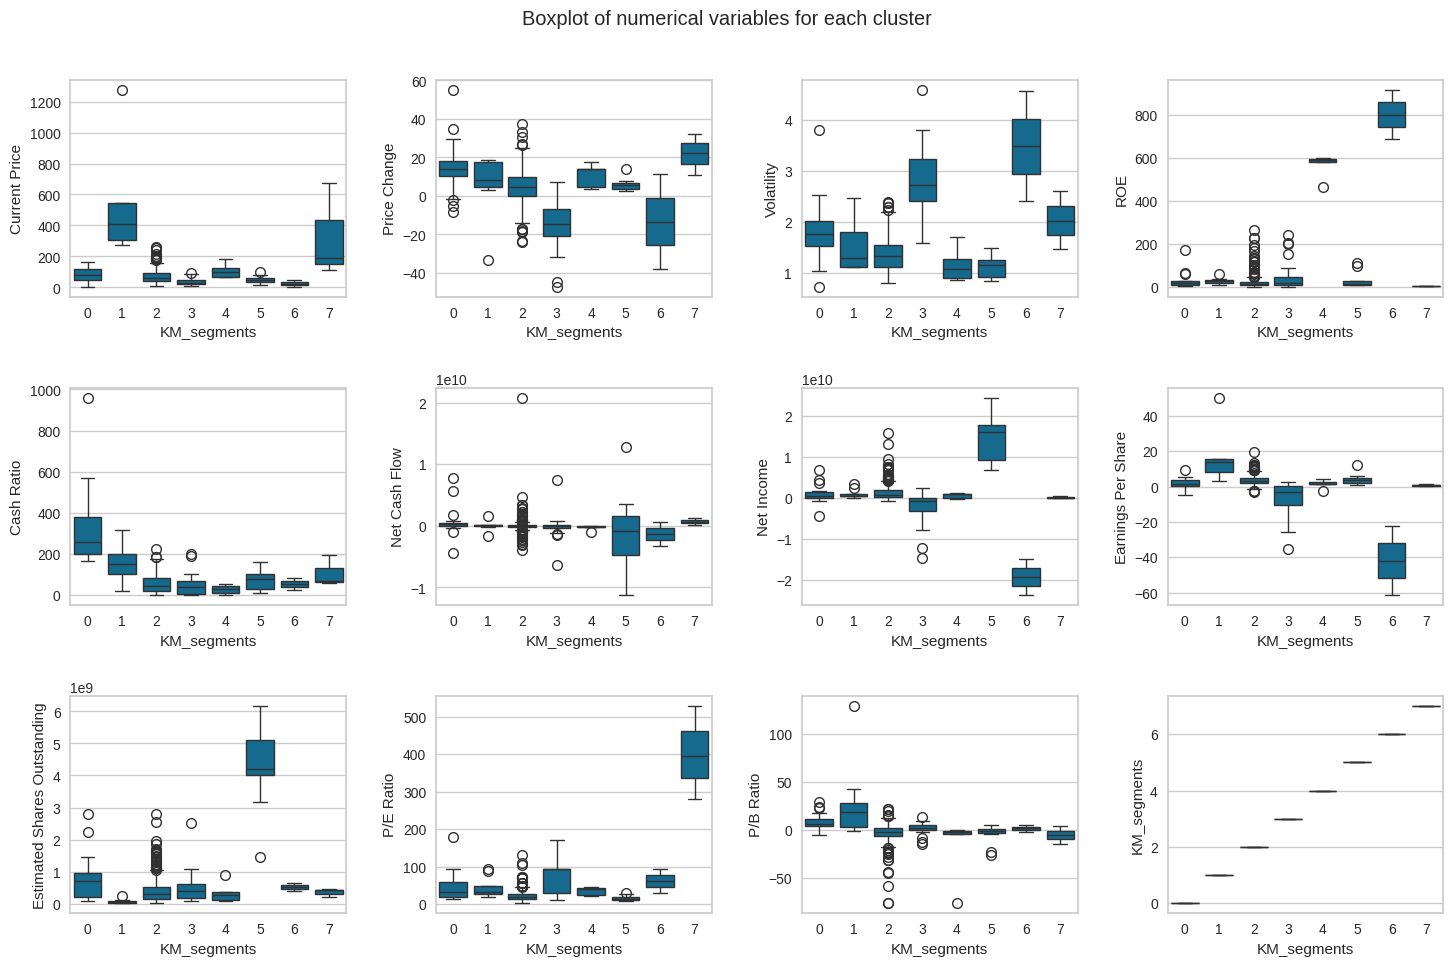

In [79]:
plt.figure(figsize=(15, 10))
plt.suptitle("Boxplot of numerical variables for each cluster")

for i, variable in enumerate(num_cols):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(data=dfK, x="KM_segments", y=variable)

plt.tight_layout(pad=2.0)

###Insights

- Cluster 0: 20 Companies
  - Current Price is Moderate
  - Price Change is  High to Very High
  - Volatility is Moderate
  - ROE is Low to Moderate
  - Cash Ratio is Very High
  - Net Cash Flow is High to Very High
  - Net Income is Moderate to Very High
  - Earnings Per Share is Moderate
  - Estimated Shares Outstanding is High to Very High
  - P/E Ratio is Moderate to High
  - P/B Ratio is High to Very High

- Cluster 1: 8 Companies
  - Current Price is Very High
  - Price Change is Moderate
  - Volatility is Moderate
  - ROE is Low to Moderate
  - Cash Ratio is High to Very High
  - Net Cash Flow is Moderate
  - Net Income is High
  - Earnings Per Share is Very High
  - Estimated Shares Outstanding is Very Low
  - P/E Ratio is Moderate
  - P/B Ratio is Very High

- Cluster 2: 264 Companies
  - Current Price is Moderate
  - Price Change is Low to Moderate
  - Volatility is Low to Moderate
  - ROE is Low
  - Cash Ratio is Moderate
  - Net Cash Flow is Moderate
  - Net Income is High to Very High
  - Earnings Per Share is Moderate to High
  - Estimated Shares Outstanding is Moderate
  - P/E Ratio is Low
  - P/B Ratio is Moderate

- Cluster 3: 27 Companies
  - Current Price is Low
  - Price Change is Very Low
  - Volatility is High to Very High
  - ROE is Moderate to High
  - Cash Ratio is Low to Moderate
  - Net Cash Flow is Moderate
  - Net Income is Low to Very Low
  - Earnings Per Share is Low to Very Low
  - Estimated Shares Outstanding is Moderate to High
  - P/E Ratio is High
  - P/B Ratio is Moderate to High

- Cluster 4: 5 Companies
  - Current Price is Moderate to High
  - Price Change is Moderate to High
  - Volatility is Low to Very Low
  - ROE is High to Very High
  - Cash Ratio is Very Low
  - Net Cash Flow is Low to Moderate
  - Net Income is Moderate
  - Earnings Per Share is Low to Moderate
  - Estimated Shares Outstanding is Low
  - P/E Ratio is Low to Moderate
  - P/B Ratio is Very Low

- Cluster 5: 11 Companies
  - Current Price is Low to Moderate
  - Price Change is Moderate
  - Volatility is Very Low
  - ROE is Moderate
  - Cash Ratio is MOderate
  - Net Cash Flow is Low to Very Low
  - Net Income is Very High
  - Earnings Per Share is High to Very High
  - Estimated Shares Outstanding is Very High
  - P/E Ratio is Very Low
  - P/B Ratio is Moderate

- Cluster 6: 2 Companies
  - Current Price is Very Low
  - Price Change is Very Low
  - Volatility is Very High
  - ROE is Very High
  - Cash Ratio is Moderate
  - Net Cash Flow is Very Low
  - Net Income is Very Low
  - Earnings Per Share is Very Low
  - Estimated Shares Outstanding is Moderate to High
  - P/E Ratio is High
  - P/B Ratio is Moderate

- Cluster 7: 3 Companies
  - Current Price is High to Very High
  - Price Change is Very High
  - Volatility is Moderate to High
  - ROE is Very Low
  - Cash Ratio is Moderate to High
  - Net Cash Flow is Very High
  - Net Income is Low to Moderate
  - Earnings Per Share is Low to Moderate
  - Estimated Shares Outstanding is Low to Moderate
  - P/E Ratio is Very High
  - P/B Ratio is Low to Very Low


## Hierarchical Clustering

In [115]:
#create a copy of scaled data set for Hierarchical Clustering
hc_df = subset_scaled_df.copy()

###Checking Cophenetic Correlation

In [116]:
%%time
#List Distance Metrics
distance_metrics= ['euclidean', 'chebyshev', 'mahalanobis', 'cityblock']

#list of Linkage Methods
linkage_methods= ['single', 'complete', 'average', 'weighted']

high_cophenet_corr=0
high_dm_lm = [0,0]

for dm in distance_metrics:
  for lm in linkage_methods:
    Z= linkage(hc_df, metric=dm, method=lm)
    c, coph_dists = cophenet(Z, pdist(hc_df))
    print("Cophenetic correlation for {} distance and {} linkage is {}.".format(dm.capitalize(), lm, c))
    if high_cophenet_corr < c:
      high_cophenet_corr= c
      high_dm_lm[0]= dm
      high_dm_lm[1]= lm


Cophenetic correlation for Euclidean distance and single linkage is 0.9232271494002922.
Cophenetic correlation for Euclidean distance and complete linkage is 0.7873280186580672.
Cophenetic correlation for Euclidean distance and average linkage is 0.9422540609560814.
Cophenetic correlation for Euclidean distance and weighted linkage is 0.8693784298129404.
Cophenetic correlation for Chebyshev distance and single linkage is 0.9062538164750717.
Cophenetic correlation for Chebyshev distance and complete linkage is 0.598891419111242.
Cophenetic correlation for Chebyshev distance and average linkage is 0.9338265528030499.
Cophenetic correlation for Chebyshev distance and weighted linkage is 0.9127355892367.
Cophenetic correlation for Mahalanobis distance and single linkage is 0.925919553052459.
Cophenetic correlation for Mahalanobis distance and complete linkage is 0.7925307202850002.
Cophenetic correlation for Mahalanobis distance and average linkage is 0.9247324030159736.
Cophenetic correla

In [82]:
# printing the combination of distance metric and linkage method with the highest cophenetic correlation
print(
    "Highest cophenetic correlation is {}, which is obtained with {} distance and {} linkage.".format(
        high_cophenet_corr, high_dm_lm[0].capitalize(), high_dm_lm[1]
    )
)

Highest cophenetic correlation is 0.9422540609560814, which is obtained with Euclidean distance and average linkage.


- Since the highest cophenetic distance is Euclidean we can explore few more linkage methods which only apply when the distance is Euclidean, namely: Ward and Centroid Linkage

In [117]:
%%time

#list of Linkage Methods
linkage_methods= ['single', 'complete', 'average', 'weighted', 'ward', 'centroid']

high_cophenet_corr=0
high_dm_lm = [0,0]


for lm in linkage_methods:
  Z= linkage(hc_df, metric='euclidean', method=lm)
  c, coph_dists = cophenet(Z, pdist(hc_df))
  print("Cophenetic correlation for {} distance and {} linkage is {}.".format(dm.capitalize(), lm, c))
  if high_cophenet_corr < c:
    high_cophenet_corr= c
    high_dm_lm[0]= 'Euclidean'
    high_dm_lm[1]= lm

Cophenetic correlation for Cityblock distance and single linkage is 0.9232271494002922.
Cophenetic correlation for Cityblock distance and complete linkage is 0.7873280186580672.
Cophenetic correlation for Cityblock distance and average linkage is 0.9422540609560814.
Cophenetic correlation for Cityblock distance and weighted linkage is 0.8693784298129404.
Cophenetic correlation for Cityblock distance and ward linkage is 0.7101180299865353.
Cophenetic correlation for Cityblock distance and centroid linkage is 0.9314012446828154.
CPU times: user 33.7 ms, sys: 890 µs, total: 34.6 ms
Wall time: 31.5 ms


In [118]:
# printing the combination of distance metric and linkage method with the highest cophenetic correlation
print(
    "Highest cophenetic correlation is {}, which is obtained with {} linkage.".format(
        high_cophenet_corr, high_dm_lm[1]
    )
)

Highest cophenetic correlation is 0.9422540609560814, which is obtained with average linkage.


**We observe cophenetic correlation is highest with Euclidean Distance and Average Linkage**

###Checking Dendrograms

CPU times: user 4.87 s, sys: 42 ms, total: 4.91 s
Wall time: 5.01 s


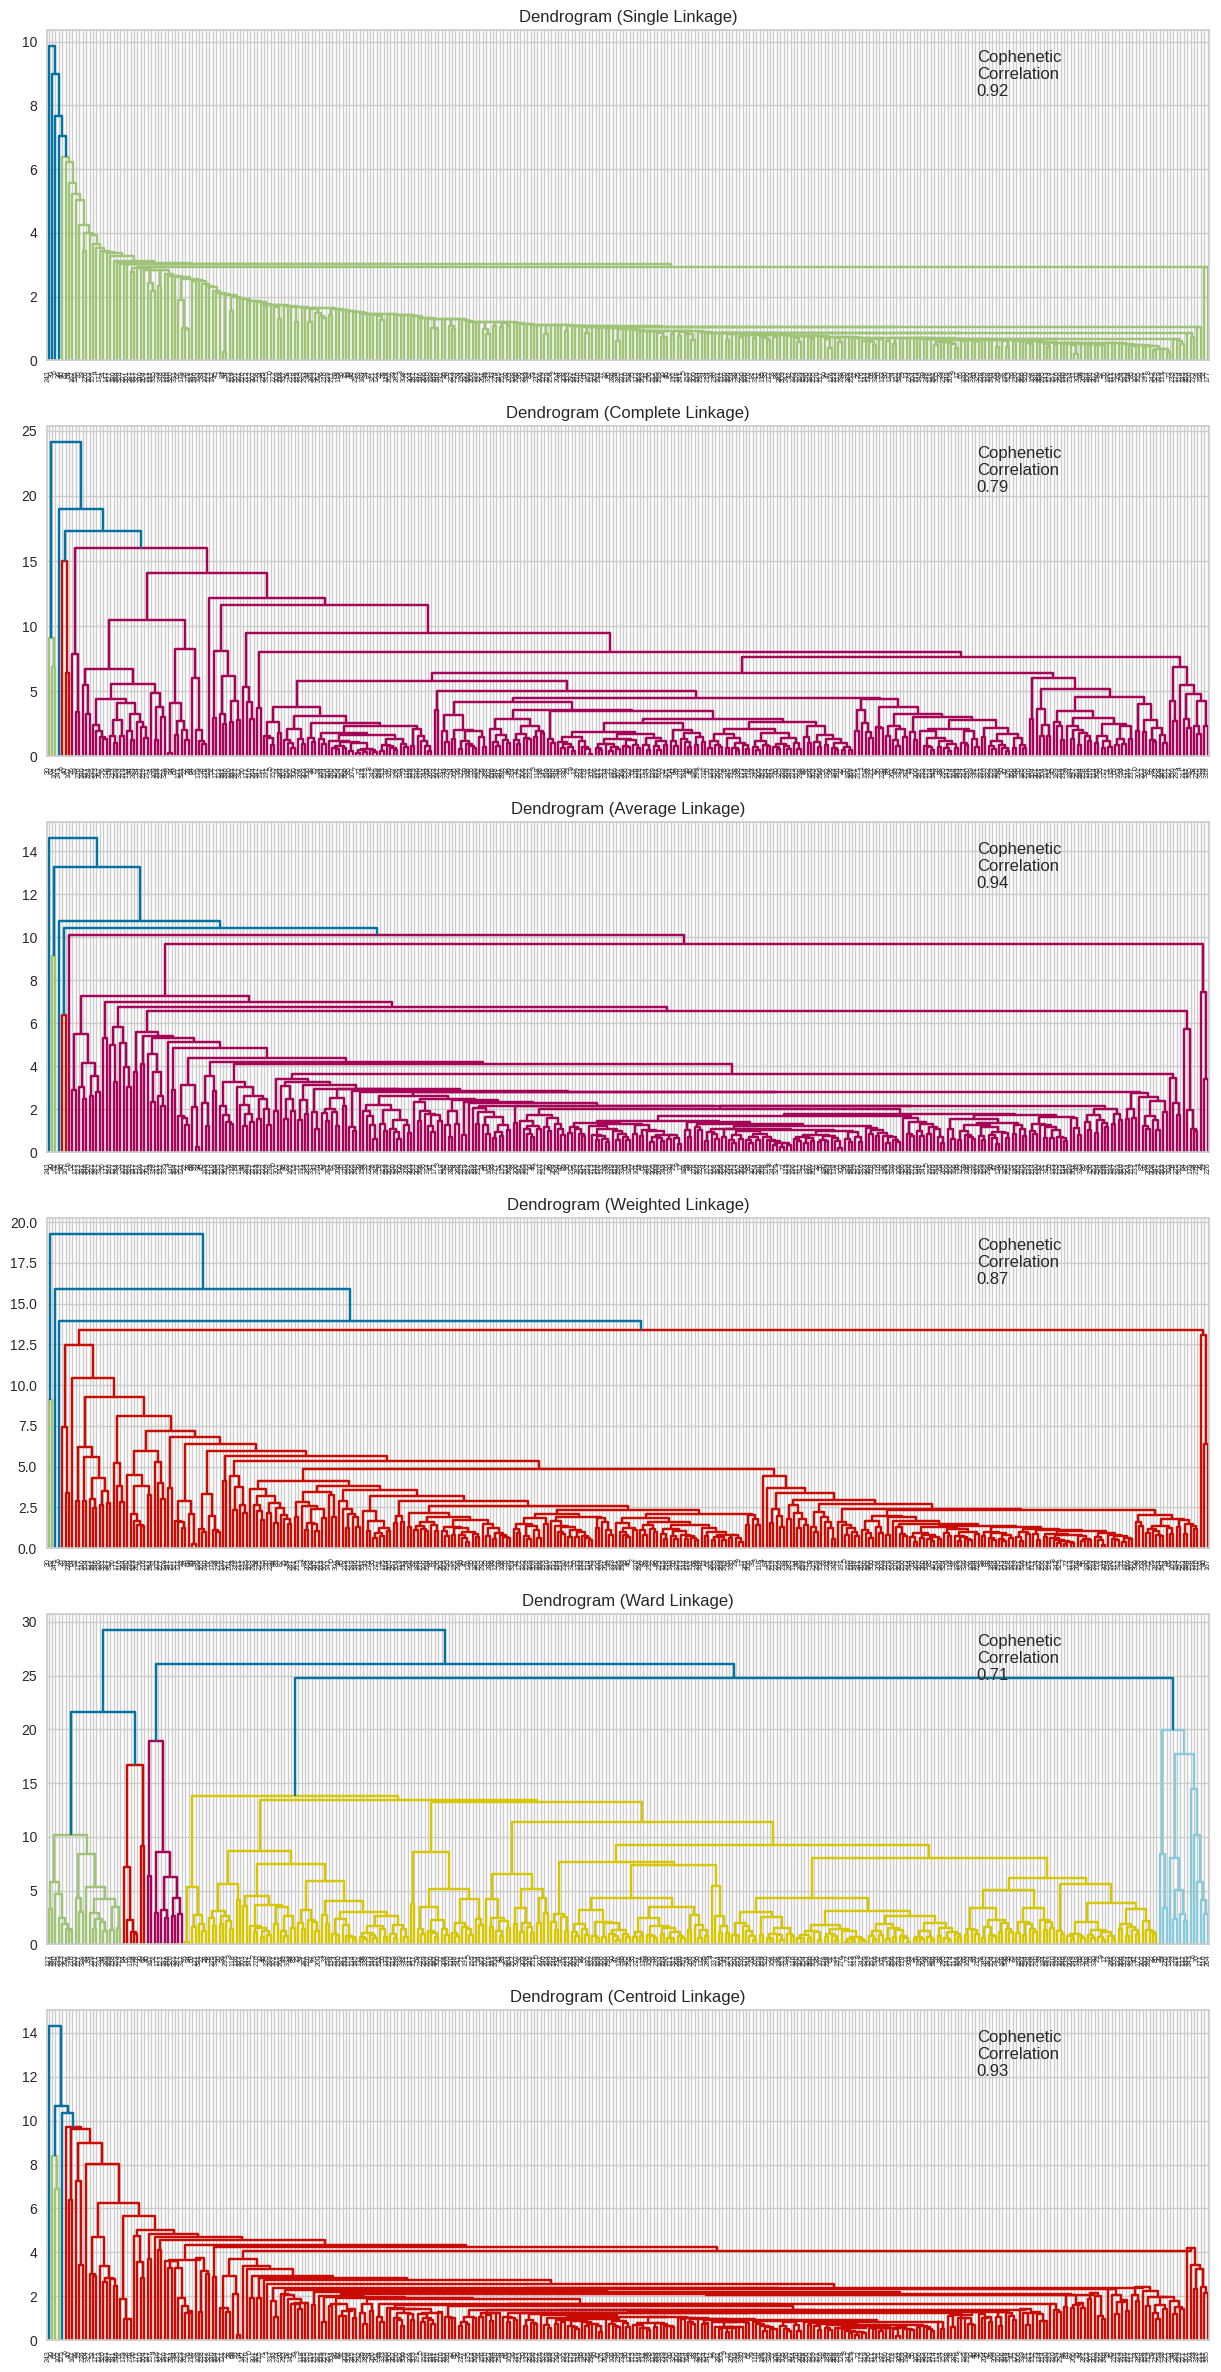

In [119]:
%%time

#Using the variable linkage_methods defined when calculating the highest cophenetic correlation

#lists to save results of cophenetic correlation calculation
compare_cols= ['Linkage', 'Cophenetic Coefficient']
compare = []

#to create a subplot image
fig, axs = plt.subplots(len(linkage_methods), 1 , figsize=(15,30))

#We will enumerate through the list of linkage methods
#For each linkage method, we will plot a dendrogram and calculate the cophenetic correlation
for i, method in enumerate(linkage_methods):
 Z= linkage(hc_df, metric='euclidean', method=method)

 dendrogram(Z, ax=axs[i])
 axs[i].set_title(f"Dendrogram ({method.capitalize()} Linkage)")

 coph_corr, coph_dist = cophenet(Z, pdist(hc_df))
 axs[i].annotate(
     f"Cophenetic\nCorrelation\n{coph_corr:0.2f}", (.80,.80), xycoords='axes fraction'
 )

 compare.append([method, coph_corr])


In [120]:
# create and print a dataframe to compare cophenetic correlations for different linkage methods
df_cc = pd.DataFrame(compare, columns=compare_cols)
df_cc = df_cc.sort_values(by="Cophenetic Coefficient")
df_cc

,Linkage,Cophenetic Coefficient
4,ward,0.710118
1,complete,0.787328
3,weighted,0.869378
0,single,0.923227
5,centroid,0.931401
2,average,0.942254


**Observations**

- The cophenetic correlation is the highest with Average, Centroid and Single Linkage
- We will move ahead with average linkage
- 7 clusters appreas to be an appropriate number of clusters from the dendrogram

### Create Final Model for Hierarchical Clustering

In [198]:
#set and fit the final HC Model
HCmodel = AgglomerativeClustering( n_clusters= 7, affinity= 'euclidean', linkage = 'average')
HCmodel.fit(hc_df)

AgglomerativeClustering(affinity='euclidean', linkage='average', n_clusters=7)

In [199]:
#create a copy of the original data to apply the hierarchical clustering model to
dfHC = df.copy()

#adding hierarchical cluster labels to the original and scaled dataframes
hc_df['HC_segments']= HCmodel.labels_
dfHC['HC_segments']= HCmodel.labels_

###Cluster Profiling

In [200]:
#Set a variable for numerical columns in the HC data frame
num_cols_HC = dfHC.select_dtypes(include=np.number).columns.tolist()

In [201]:
#Check to see that this was done correctly
num_cols_HC

['Current Price',
 'Price Change',
 'Volatility',
 'ROE',
 'Cash Ratio',
 'Net Cash Flow',
 'Net Income',
 'Earnings Per Share',
 'Estimated Shares Outstanding',
 'P/E Ratio',
 'P/B Ratio',
 'HC_segments']

In [202]:
#Grouping the data frame by cluster labels
HC_cluster_profile = dfHC[num_cols_HC].groupby('HC_segments').mean()

In [203]:
#Grouping Companies by the cluster label
HC_cluster_profile['count_in_each_segment'] = (dfHC.groupby('HC_segments')['Security'].count().values)

In [204]:
#Display the cluster profiles
HC_cluster_profile.style.highlight_max(color="lightgreen", axis=0)

,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio,count_in_each_segment
HC_segments,,,,,,,,,,,,
0,24.485001,-13.351992,3.482611,802.000000,51.000000,-1292500000.000000,-19106500000.000000,-41.815000,519573983.250000,60.748608,1.565141,2
1,434.193329,-2.736323,1.572329,22.000000,193.000000,11241666.666667,553647666.666667,13.360000,45046133.056667,32.272589,62.957805,3
2,327.006671,21.917380,2.029752,4.000000,106.000000,698240666.666667,287547000.000000,0.750000,366763235.300000,400.989188,-5.322376,3
3,72.346760,4.005659,1.511667,35.728659,65.262195,-39915457.317073,1555645795.731707,2.827363,565486893.797348,29.068120,-2.341739,328
4,104.660004,16.224320,1.320606,8.000000,958.000000,592000000.000000,3669000000.000000,1.310000,2800763359.000000,79.893133,5.884467,1
5,1274.949951,3.190527,1.268340,29.000000,184.000000,-1671386000.000000,2551360000.000000,50.090000,50935516.070000,25.453183,-1.052429,1
6,25.640000,11.237908,1.322355,12.500000,130.500000,16755500000.000000,13654000000.000000,3.295000,2791829362.100000,13.649696,1.508484,2


In [205]:
# let's see the names of the countries in each cluster
for cl in dfHC["HC_segments"].unique():
    print("In cluster {}, the following companies are present:".format(cl))
    print(dfHC[dfHC["HC_segments"] == cl]["Security"].unique())
    print()

In cluster 3, the following companies are present:
['American Airlines Group' 'AbbVie' 'Abbott Laboratories'
 'Adobe Systems Inc' 'Analog Devices, Inc.' 'Archer-Daniels-Midland Co'
 'Ameren Corp' 'American Electric Power' 'AFLAC Inc'
 'American International Group, Inc.' 'Apartment Investment & Mgmt'
 'Assurant Inc' 'Arthur J. Gallagher & Co.' 'Akamai Technologies Inc'
 'Albemarle Corp' 'Alaska Air Group Inc' 'Allstate Corp' 'Allegion'
 'Applied Materials Inc' 'AMETEK Inc' 'Affiliated Managers Group Inc'
 'Amgen Inc' 'Ameriprise Financial' 'American Tower Corp A'
 'AutoNation Inc' 'Anthem Inc.' 'Aon plc' 'Anadarko Petroleum Corp'
 'Amphenol Corp' 'Arconic Inc' 'Activision Blizzard'
 'AvalonBay Communities, Inc.' 'Broadcom'
 'American Water Works Company Inc' 'American Express Co' 'Boeing Company'
 'Baxter International Inc.' 'BB&T Corporation' 'Bard (C.R.) Inc.'
 'Baker Hughes Inc' 'BIOGEN IDEC Inc.' 'The Bank of New York Mellon Corp.'
 'Ball Corp' 'Bristol-Myers Squibb' 'Boston Scient

In [206]:
#Check to see how many of each GICS sector are in each cluster
dfHC.groupby(["HC_segments", "GICS Sector"])['Security'].count()

HC_segments  GICS Sector                
0            Energy                          2
1            Consumer Discretionary          1
             Health Care                     1
             Information Technology          1
2            Consumer Discretionary          1
             Health Care                     1
             Information Technology          1
3            Consumer Discretionary         37
             Consumer Staples               19
             Energy                         28
             Financials                     48
             Health Care                    38
             Industrials                    53
             Information Technology         29
             Materials                      20
             Real Estate                    27
             Telecommunications Services     5
             Utilities                      24
4            Information Technology          1
5            Consumer Discretionary          1
6            Financ

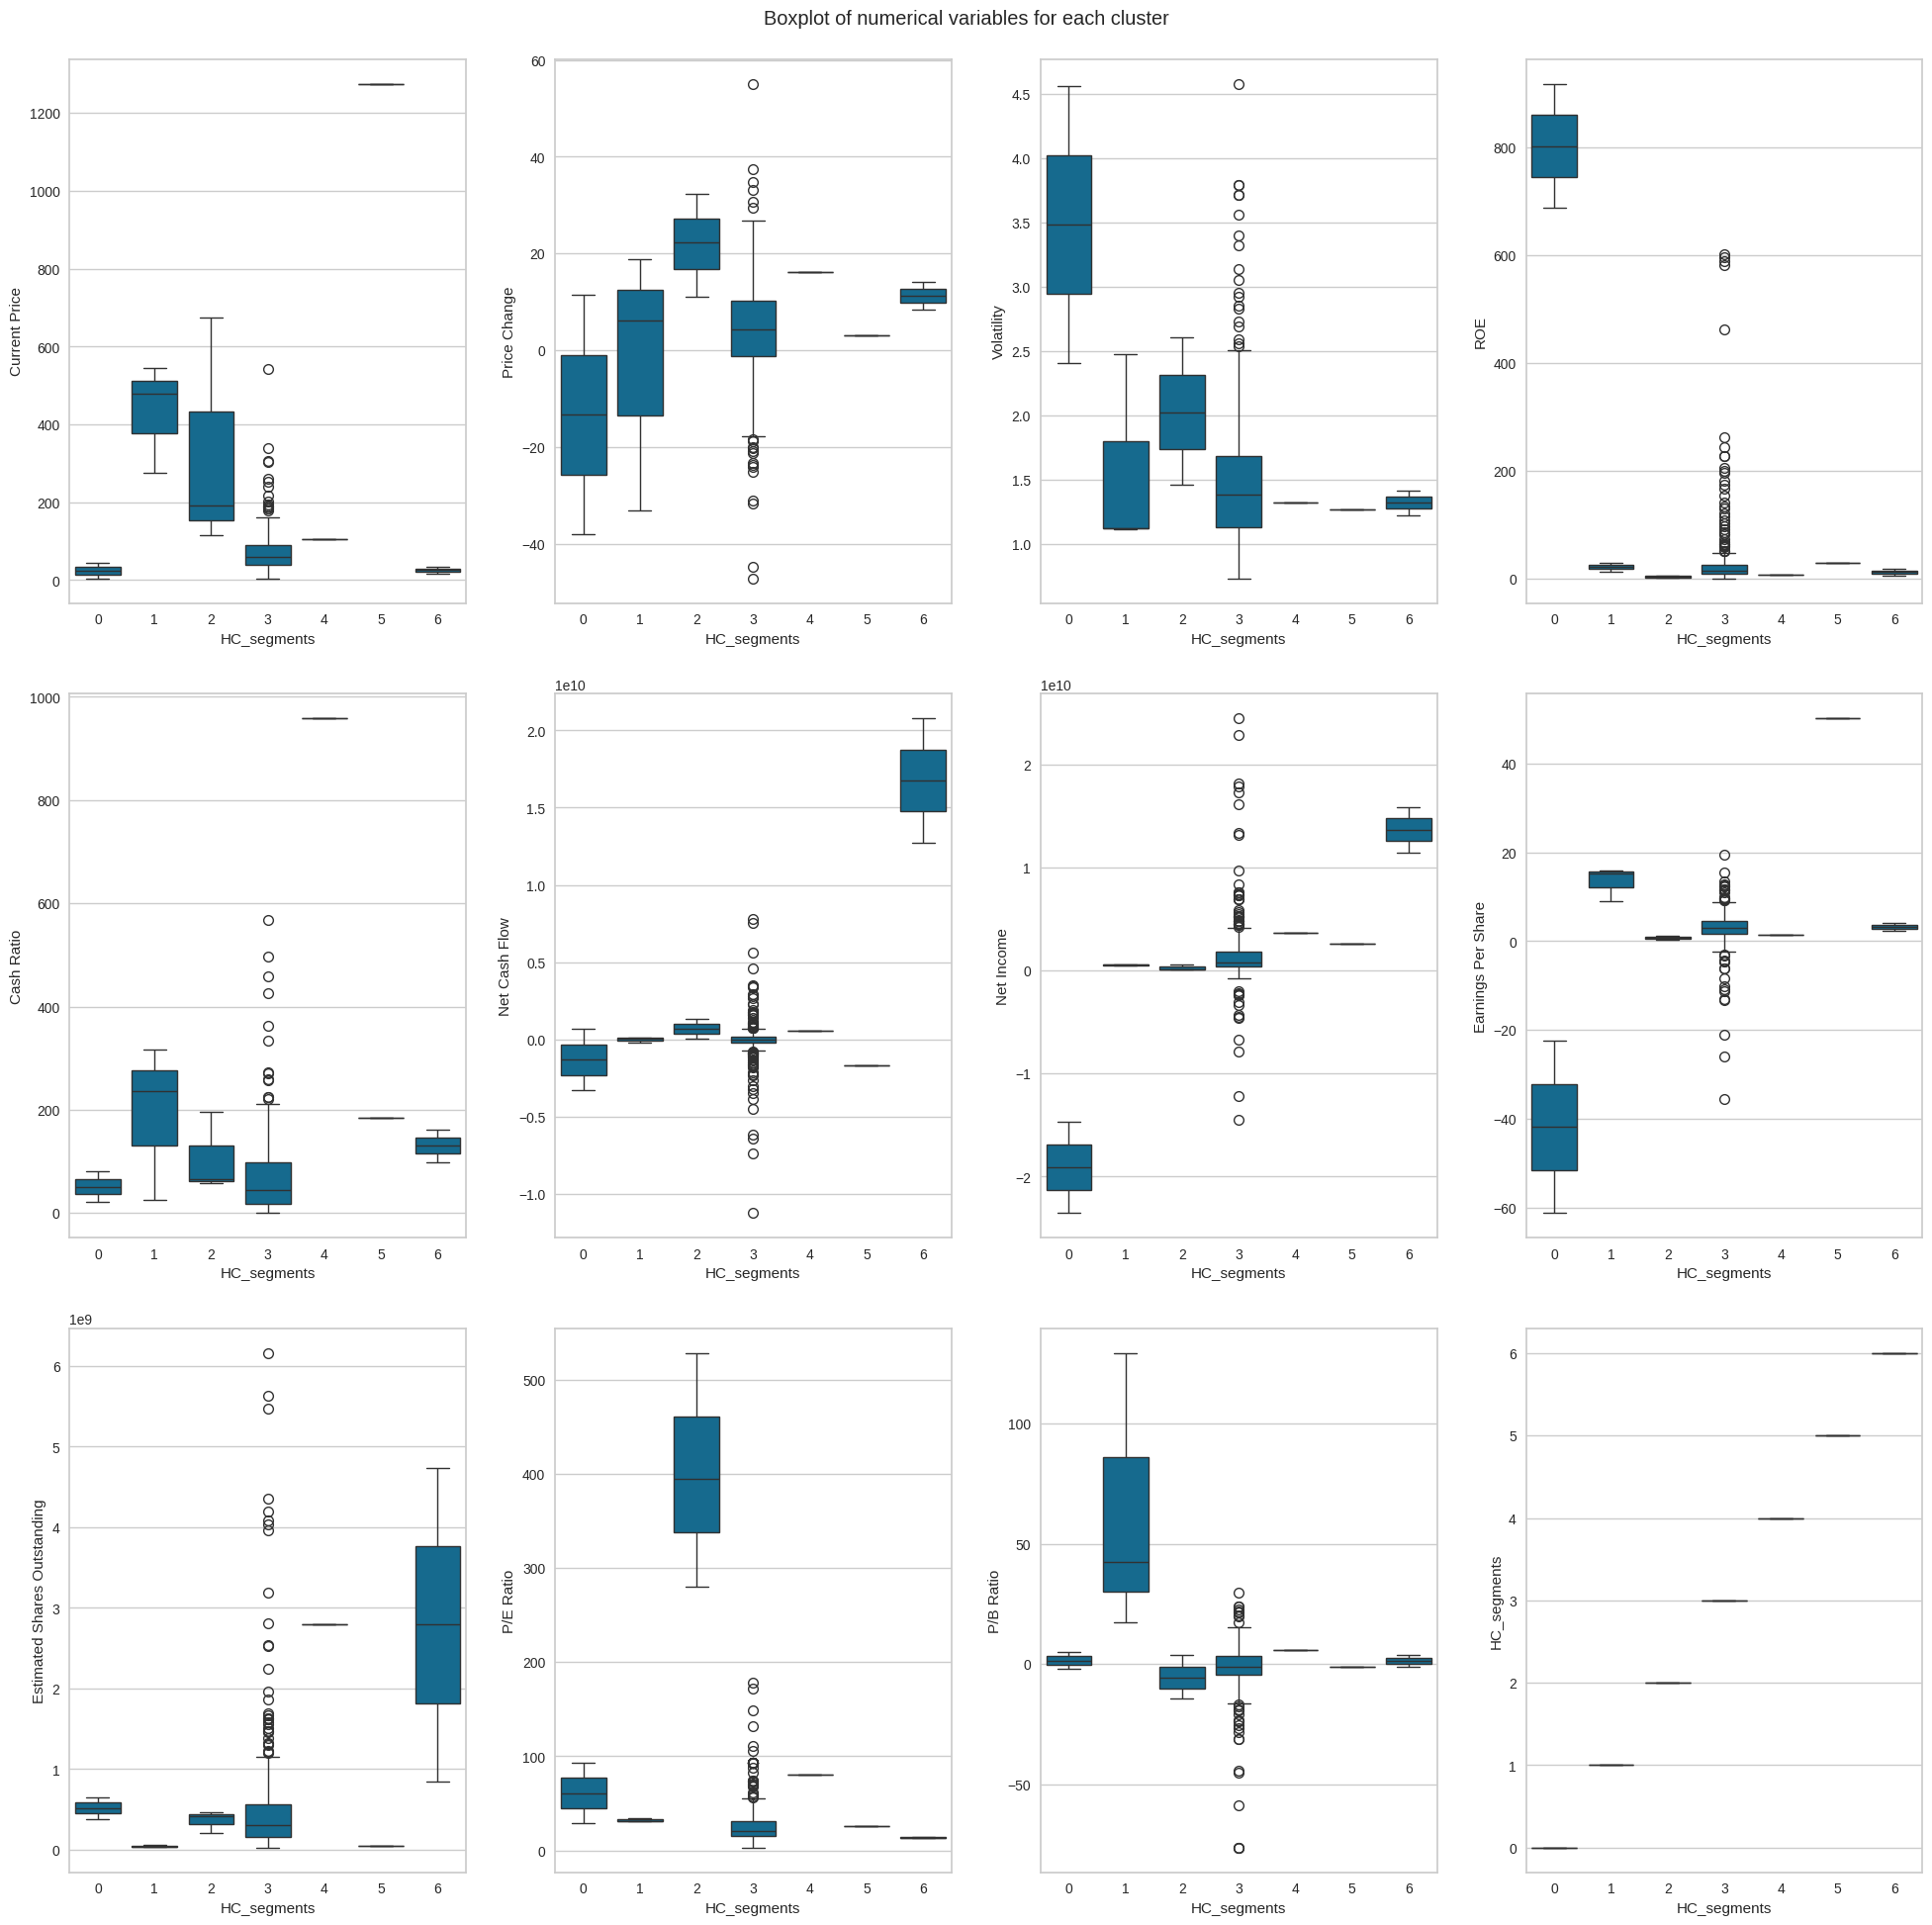

In [207]:
plt.figure(figsize=(20, 20))
plt.suptitle("Boxplot of numerical variables for each cluster")

for i, variable in enumerate(num_cols_HC):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(data=dfHC, x="HC_segments", y=variable)

plt.tight_layout(pad=2.0)

- Cluster 0: 2 Companies
  - Current Price is Very Low
  - Price Change is Very Low
  - Volatility is Very High
  - ROE is Very High
  - Cash Ratio is Very Low
  - Net Cash Flow is Low to Very Low
  - Net Income is Very Low
  - Earnings Per Share is Very Low
  - Estimated Shares Outstanding is Moderate to High
  - P/E Ratio is Moderate to High
  - P/B Ratio is Moderate

- Cluster 1: 3 Companies
  - Current Price is High to Very High
  - Price Change is Low to Very Low
  - Volatility is Moderate
  - ROE is Morderate
  - Cash Ratio is High
  - Net Cash Flow is Low to Moderate
  - Net Income is Low to Moderate
  - Earnings Per Share is High to Very High
  - Estimated Shares Outstanding Low to Very Low
  - P/E Ratio is Moderate
  - P/B Ratio is Very High

- Cluster 2: 3 Companies
  - Current Price is High
  - Price Change is Very High
  - Volatility is High
  - ROE is Very Low
  - Cash Ratio is Low to Moderate
  - Net Cash Flow is High to very High
  - Net Income is Low
  - Earnings Per Share is Low to Very Low
  - Estimated Shares Outstanding is Low to Moderate
  - P/E Ratio is Very High
  - P/B Ratio is Very Low

- Cluster 3: 328 Companies
  - Current Price is Low to Moderate
  - Price Change is Moderate
  - Volatility is Moderate
  - ROE is High
  - Cash Ratio is Low to Very Low
  - Net Cash Flow is Low to Moderate
  - Net Income is Moderate
  - Earnings Per Share is Moderate
  - Estimated Shares Outstanding is Moderate to High
  - P/E Ratio is Moderate
  - P/B Ratio is Low to Moderate

- Cluster 4: 1 Company
  - Current Price is Moderate
  - Price Change is High
  - Volatility is Low
  - ROE is Low to Very Low
  - Cash Ratio is Very High
  - Net Cash Flow is Moderate to High
  - Net Income is High
  - Earnings Per Share is Moderate
  - Estimated Shares Outstanding is Very High
  - P/E Ratio is High to Very High
  - P/B Ratio is High to Very High

- Cluster 5: 1 Company
  - Current Price is Very High
  - Price Change is Low to Moderate
  - Volatility is Very Low
  - ROE is Moderate to High
  - Cash Ratio is Moderate to High
  - Net Cash Flow is Very Low
  - Net Income is Moderate
  - Earnings Per Share is Very High
  - Estimated Shares Outstanding is Low
  - P/E Ratio is Low to Moderate
  - P/B Ratio is Low to Moderate

- Cluster 6 : 2 Companies
  - Current Price is Low to Very Low
  - Price Change is Moderate to High
  - Volatility is Low
  - ROE is Low
  - Cash Ratio is Moderate
  - Net Cash Flow is Very High
  - Net Income is Very High
  - Earnings Per Share is Moderate to High
  - Estimated Shares Outstanding is High to Very High
  - P/E Ratio is Very Low
  - P/B Ratio is Low to Moderate



## K-means vs Hierarchical Clustering

- The K-means Clustering model seemed to perform better than the Hierarchical Clustering model. The K-means was able to segment the companies into more clusters while retaining a good performance on the evaluation metric of silhouette score. The Hierarchical Clustering Model ended with 1 large cluster and numerous clusters ranging from 1-3 companies, so it didn't do a great job at clustering the companies, despite its cophenetic correlation score being very good.

- The K-means clustering took less time to execute and yielded what seems to be a better result for splitting the companies into clusters. The K-means was also able to seperate the clusters in a more distinct way.

- The K-means method yielded 8 clusters while the Hierarchical method yielded 7 clusters with less segmentation.

- The two methods yielded some similar clusters namely:
  - K-means cluster: 6 and HC Cluster: 0
  - K-means cluster: 2 and HC Cluster: 3 (largest clusters)
  - K-means cluster: 7 and HC Cluster: 2

- K-means company counts per cluster (For Cluster attributes reference insights in the k-means cluster profiling section)
- 0: 20
- 1: 8
- 2: 264
- 3: 27
- 4: 5
- 5: 11
- 6: 2
- 7: 3

- Hierarchical company counts per Cluster (For Cluster attributes reference insights in the hierarchical cluster profiling section)
- 0: 2
- 1: 3
- 2: 3
- 3: 328
- 4: 1
- 5: 1
- 6: 2



## Actionable Insights and Recommendations

- The K-means method was able to segment the companies into disctinct clusters with varying characteristics based on the independent variables given in the original data set.
- The different clusters can be used to guide diversification on a portfolio based on a specific persons means to purchase stocks, investment goals and risk tolerance.